# Univariate Time Series Models IV: Trends and Unit Roots
**HS 821 · Lecture 10 · Topics in Time Series Econometrics**

**Sunil Paul**

October 2026 · R 4.6

Lecture 9 ran the Box–Jenkins cycle on **stationary** series. Most economic and financial series are not stationary: GDP, prices, exchange rates and stock indices trend, and their variance grows with the sample. Step 2 of the identification checklist in Lecture 9 — *differencing removes stochastic trends* — was left for later. This lecture covers it:

1. **Trends** — deterministic versus stochastic trends, and the random walk as the canonical stochastic trend (Sections 1–2).
2. **Unit roots and integration** — what a unit root does to the lag polynomial, the impulse response and the ARIMA($p,d,q$) model, and whether to detrend or to difference (Sections 3–4).
3. **Testing** — why the usual $t$-test fails under a unit root, the Dickey–Fuller family of tests, a sequential testing strategy worked through on six simulated series, and the complementary Phillips–Perron and KPSS tests (Sections 5–8).
4. **Practice and newer developments** — size, power and lag length; efficient (GLS) detrending, structural breaks, uncertainty about the trend, bootstrap methods, explosive roots and bubble detection, and a map of other modern strands (Sections 9–10).


## Setup

We keep the plotting helpers of Lectures 6–9 that this lecture needs  Unit-root tests come from the **urca** package (Pfaff 2008):

- `ur.df()` — Dickey–Fuller and augmented Dickey–Fuller tests, with the $\Phi$ statistics;
- `ur.pp()` — Phillips–Perron;
- `ur.kpss()` — the KPSS stationarity test;
- `ur.ers()` — the Elliott–Rothenberg–Stock DF-GLS and point-optimal tests;
- `ur.za()` — the Zivot–Andrews test with an endogenous break;
- `punitroot()` — MacKinnon (1996) $p$-values for Dickey–Fuller statistics.

> **R convention.** `ur.df(y, type, lags, selectlags)`: `type = "none"`, `"drift"` or `"trend"` adds nothing, a constant, or a constant and a linear trend to the test regression. With `selectlags = "Fixed"` (the default) `lags` is the number of lagged differences; with `"AIC"` or `"BIC"` it is the **maximum**, and urca searches $1,\dots,$`lags` — it never selects zero lags. The statistics are stored as `tau1`; `tau2, phi1`; `tau3, phi2, phi3`. Critical values are read from the Dickey–Fuller tables at the next tabulated sample size **above** yours (25, 50, 100, 250, 500, ∞), so in borderline cases look at the MacKinnon $p$-value that `df_report()` prints. Beware that `tseries::adf.test()` always includes a constant and a trend and uses a different default lag; do not mix the two up.

In [2]:

# ------------------------------------------------------------------
# Setup: plotting helpers (Lectures 6-9) + three new ones
# ------------------------------------------------------------------
suppressPackageStartupMessages({
  library(ggplot2)
  library(gridExtra)
  library(urca)        # ur.df, ur.pp, ur.kpss, ur.ers, ur.za, punitroot (Pfaff 2008)
})
options(repr.plot.width = 10, repr.plot.height = 6)

# Time-series line plot; optional dashed reference line at the mean.
ts_plot <- function(x, mu = NULL, title = NULL) {
  time_idx <- if (is.ts(x)) as.numeric(time(x)) else seq_along(x)
  df <- data.frame(time = time_idx, value = as.numeric(x))
  p <- ggplot(df, aes(time, value)) +
    theme_classic() + geom_line() + labs(x = "Time", y = NULL, title = title)
  if (!is.null(mu)) p <- p + geom_hline(yintercept = mu, linetype = "dashed")
  p
}

# Sample ACF / PACF with approximate +/- 2/sqrt(T) bands.
sample_acf_plot <- function(x, L = 20, title = NULL, by = 3) {
  a  <- acf(x, plot = FALSE, lag.max = L)
  df <- data.frame(lag = as.numeric(a$lag)[-1], acf = as.numeric(a$acf)[-1])
  b  <- 2 / sqrt(length(x))
  ggplot(df, aes(lag, acf)) + theme_classic() +
    geom_hline(yintercept = 0) +
    geom_segment(aes(xend = lag, y = 0, yend = acf), linewidth = 1) +
    geom_point(size = 2) +
    geom_hline(yintercept = c(b, -b), linetype = "dashed", colour = "red") +
    scale_x_continuous(breaks = seq(0, L, by = by)) +
    labs(x = "Lag", y = "Sample ACF", title = title)
}

sample_pacf_plot <- function(x, L = 20, title = NULL, by = 3) {
  a  <- pacf(x, plot = FALSE, lag.max = L)
  df <- data.frame(lag = as.numeric(a$lag), acf = as.numeric(a$acf))
  b  <- 2 / sqrt(length(x))
  ggplot(df, aes(lag, acf)) + theme_classic() +
    geom_hline(yintercept = 0) +
    geom_segment(aes(xend = lag, y = 0, yend = acf), linewidth = 1) +
    geom_point(size = 2) +
    geom_hline(yintercept = c(b, -b), linetype = "dashed", colour = "red") +
    scale_x_continuous(breaks = seq(0, L, by = by)) +
    labs(x = "Lag", y = "Sample PACF", title = title)
}

# Theoretical impulse response = Wold coefficients psi_0=1, psi_1, psi_2, ...
irf_plot <- function(ar = numeric(0), ma = numeric(0), h = 20, title = NULL) {
  psi <- c(1, ARMAtoMA(ar = ar, ma = ma, lag.max = h))
  df  <- data.frame(horizon = 0:h, response = psi)
  ggplot(df, aes(horizon, response)) + theme_classic() +
    geom_hline(yintercept = 0) +
    geom_segment(aes(xend = horizon, y = 0, yend = response)) +
    geom_point() +
    scale_x_continuous(breaks = seq(0, h, by = 4)) +
    labs(x = "Horizon after a unit innovation", y = "Response", title = title)
}

# Roots of a lag polynomial on the complex plane, with the unit circle.
# CHANGED: roots on the circle (|z| = 1 up to rounding) get their own colour.
roots_plot <- function(roots, title = NULL, tol = 1e-6) {
  theta <- seq(0, 2 * pi, length.out = 400)
  circ  <- data.frame(x = cos(theta), y = sin(theta))
  where <- ifelse(abs(Mod(roots) - 1) < tol, "on the circle",
                  ifelse(Mod(roots) > 1, "outside", "inside"))
  df    <- data.frame(Real = Re(roots), Imaginary = Im(roots), where = where)
  ggplot() + theme_classic() +
    geom_path(data = circ, aes(x, y), colour = "grey55") +
    geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
    geom_point(data = df, aes(Real, Imaginary, colour = where), size = 3) +
    scale_colour_manual(values = c(outside = "black", inside = "red",
                                   `on the circle` = "blue"), name = NULL) +
    coord_equal() +
    labs(x = "Real part", y = "Imaginary part", title = title)
}

# NEW. A series and its sample ACF side by side: the first two pictures to look at.
ts_acf_panel <- function(x, title = NULL, L = 20, mu = NULL) {
  grid.arrange(ts_plot(x, mu = mu, title = title),
               sample_acf_plot(x, L = L, title = "Sample ACF"), ncol = 2)
}

# NEW. (Augmented) Dickey-Fuller test with urca::ur.df(), reported the way we read it:
# (i) the test regression, (ii) each statistic against its 5% critical value, and
# for tau the MacKinnon (1996) p-value computed for the actual number of observations.
df_report <- function(y, type = c("none", "drift", "trend"), lags = 0,
                      selectlags = c("Fixed", "AIC", "BIC"), label = NULL) {
  type <- match.arg(type); selectlags <- match.arg(selectlags)
  fit  <- ur.df(as.numeric(y), type = type, lags = lags, selectlags = selectlags)
  co   <- summary(fit)@testreg$coefficients[, 1:3, drop = FALSE]
  rn   <- sub("^z.diff.lag$", "z.diff.lag1", rownames(co))
  rn   <- sub("^z.diff.lag(\\d+)$", "alpha\\1", rn)
  rn[rn == "(Intercept)"] <- "c"; rn[rn == "z.lag.1"] <- "gamma"; rn[rn == "tt"] <- "delta (trend)"
  rownames(co) <- rn
  id   <- colnames(fit@teststat); stat <- fit@teststat[1, ]; cv5 <- fit@cval[, "5pct"]
  left <- startsWith(id, "tau"); nobs <- length(fit@res)
  pval <- rep(NA_real_, length(id))
  pval[left] <- punitroot(stat[left], N = nobs,
                          trend = c(none = "nc", drift = "c", trend = "ct")[[type]])
  tests <- data.frame(
    statistic = round(as.numeric(stat), 3), cv_5pct = as.numeric(cv5),
    p_value   = round(pval, 4),
    H0 = c(tau1 = "gamma = 0", tau2 = "gamma = 0", tau3 = "gamma = 0",
           phi1 = "c = gamma = 0", phi2 = "c = delta = gamma = 0",
           phi3 = "delta = gamma = 0")[id],
    decision = ifelse(ifelse(left, stat < cv5, stat > cv5), "reject H0", "do not reject"),
    row.names = c(tau1 = "tau", tau2 = "tau_mu", tau3 = "tau_tau",
                  phi1 = "Phi1", phi2 = "Phi2", phi3 = "Phi3")[id])
  cat(sprintf("%sDF regression: type = \"%s\", %d lagged difference(s), %d observations\n",
              if (is.null(label)) "" else paste0(label, " - "), type,
              sum(startsWith(rn, "alpha")), nobs))
  print(signif(co, 4)); cat("\n"); print(tests)
  invisible(list(fit = fit, coef = co, tests = tests))
}

# NEW. Fast DF t-ratio (no lagged differences) for Monte Carlo loops.
df_tau <- function(y, type = c("none", "drift", "trend")) {
  type <- match.arg(type)
  dy <- diff(y); ylag <- head(y, -1); n <- length(dy)
  X  <- switch(type, none  = cbind(ylag),
                     drift = cbind(1, ylag),
                     trend = cbind(1, seq_len(n), ylag))
  XtXi <- solve(crossprod(X)); b <- XtXi %*% crossprod(X, dy)
  k  <- ncol(X); s2 <- sum((dy - X %*% b)^2) / (n - k)
  b[k] / sqrt(s2 * XtXi[k, k])
}

also installing the dependencies 'lattice', 'nlme'




package 'lattice' successfully unpacked and MD5 sums checked
package 'nlme' successfully unpacked and MD5 sums checked
package 'urca' successfully unpacked and MD5 sums checked

The downloaded binary packages are in
	C:\Users\sunilpaul\AppData\Local\Temp\Rtmp2tz9V4\downloaded_packages


# 1&nbsp;&nbsp;Deterministic and stochastic trends

A **deterministic trend** is a known function of time. The simplest has constant increments, $\Delta Y_t=\delta$, with solution $Y_t=Y_0+\delta t$. 

Adding a stationary disturbance gives a **trend-stationary (TS)** process

$$
Y_t=\mu+\delta t+u_t,\qquad u_t\ \text{a stationary ARMA process}.
$$

Shocks have only **temporary** effects: $Y_t$ wanders around the line $\mu+\delta t$ and keeps returning to it. Regressing on a constant and time and keeping the residuals (**detrending**) leaves a stationary series.

A **stochastic trend** is the accumulation of past shocks. The canonical case is the random walk with drift,

$$
\Delta Y_t=\mu+\varepsilon_t
\quad\Longrightarrow\quad
Y_t=Y_0+\mu t+\sum_{i=1}^{t}\varepsilon_i ,
$$

in which every innovation has a **permanent** effect, because it enters every future $Y_{t+h}$ with weight one. $Y_t$ is not stationary but $\Delta Y_t$ is, so the process is called **difference-stationary (DS)**. More generally a DS process is $\Delta Y_t=\mu+u_t$ with $u_t$ stationary.





### Predict before you simulate

Below, a TS series ($\mu=0.8$, $\delta=0.2$, AR(1) noise with $\phi=0.8$) and a random walk with  drift  $\mu=0.2$ are drawn with $T=500$, each shown with its fitted OLS trend line. Which one keeps returning to its trend line? Which one could stay on one side of it for a hundred periods? We also count how often each series crosses its fitted trend.

Crossings of the fitted trend line:  TS = 105    DS = 28 


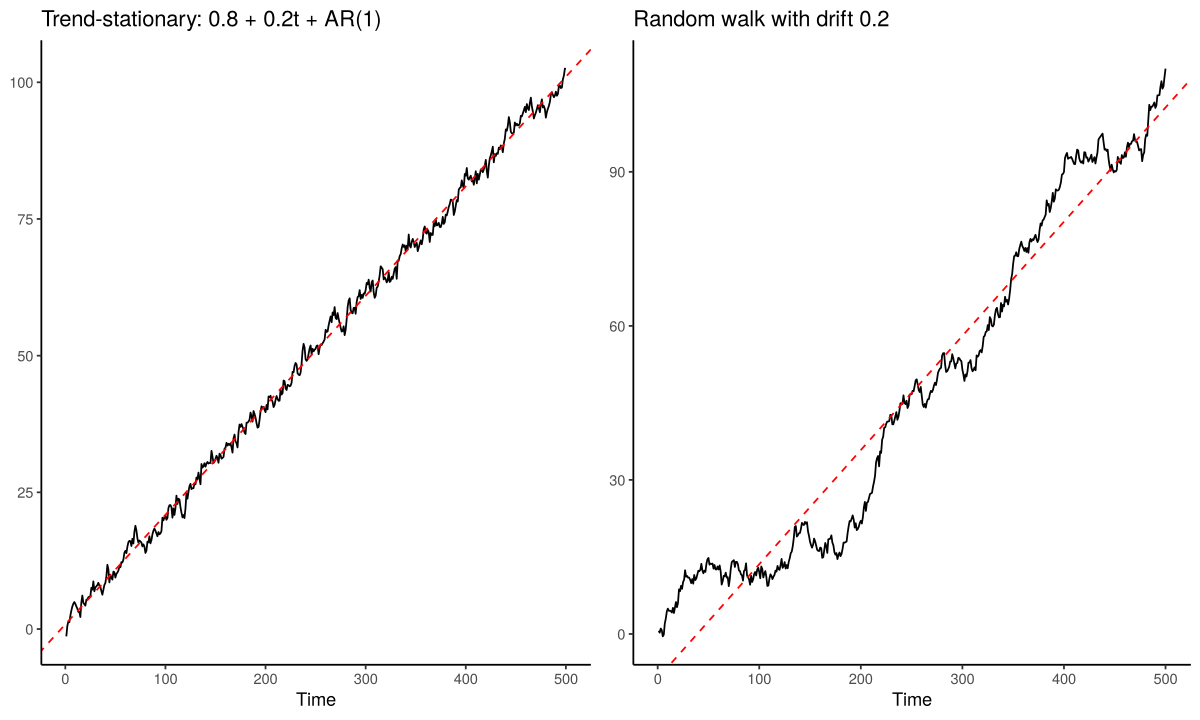

In [2]:
# A trend-stationary series and a random walk with the same drift (T = 500)
set.seed(123)
T  <- 500; tt <- 1:T
y_ts <- 0.8 + 0.2 * tt + as.numeric(arima.sim(model = list(ar = 0.8), n = T))   # TS
y_ds <- cumsum(0.2 + rnorm(T))                                                 # DS

with_trend <- function(y, title) {
  fit <- lm(y ~ tt)
  ts_plot(y, title = title) +
    geom_abline(intercept = coef(fit)[1], slope = coef(fit)[2],
                colour = "red", linetype = "dashed")
}
crossings <- function(y) sum(diff(sign(residuals(lm(y ~ tt)))) != 0)
cat("Crossings of the fitted trend line:  TS =", crossings(y_ts), "   DS =", crossings(y_ds), "\n")
grid.arrange(with_trend(y_ts, "Trend-stationary: 0.8 + 0.2t + AR(1)"),
             with_trend(y_ds, "Random walk with drift 0.2"), ncol = 2)

**Reading the output.** The trend-stationary series hugs its trend line and crosses it 105 times in 500 periods: with $\phi=0.8$ a shock has a half-life of about three periods, and the series is pulled back to the line. The random walk crosses its fitted trend only 28 times and spends stretches of a hundred periods or more on one side of it, because nothing pulls it back — every shock is permanent. The fitted line is itself misleading for the random walk: its intercept and slope are estimated from a series that has no tendency to return to any line.

# 2&nbsp;&nbsp;Random walks

## The pure random walk

A **pure random walk** satisfies $Y_t=Y_{t-1}+\varepsilon_t$, i.e. $\Delta Y_t=\varepsilon_t$ with $\varepsilon_t\sim\text{i.i.d.}(0,\sigma^2)$. Conditional on a fixed starting value $Y_0$,

$$
E(Y_t)=Y_0,\qquad
\operatorname{Var}(Y_t)=t\sigma^2,\qquad
\operatorname{Cov}(Y_t,Y_{t-j})=(t-j)\sigma^2 .
$$

The mean is constant but the variance grows without bound, so the process is not stationary. The correlation between $Y_t$ and $Y_{t-j}$ depends on $t$:

$$
\rho_{j,t}=\frac{(t-j)\sigma^2}{\sqrt{t\sigma^2\,(t-j)\sigma^2}}=\sqrt{\frac{t-j}{t}} .
$$

For fixed $j$ it tends to one as $t$ grows, and for fixed $t$ it falls only slowly as $j$ increases. This is the **correlogram signature of a unit root**: sample autocorrelations that start near one and decline roughly linearly rather than geometrically. (The sample ACF of a random walk falls somewhat faster than $\sqrt{(t-j)/t}$, because it is computed around the sample mean, but the slow decay is unmistakable.)

## The random walk with drift

Adding a constant, $\Delta Y_t=\delta+\varepsilon_t$, gives

$$
Y_t=Y_0+\delta t+\sum_{i=1}^{t}\varepsilon_i,
\qquad
E(Y_t)=Y_0+\delta t,
\qquad
\operatorname{Var}(Y_t)=t\sigma^2 .
$$

A nonzero constant in the **differences** produces a **deterministic trend in the level**, while the persistence remains stochastic. This is why the constant plays a different role in each Dickey–Fuller regression (Section 6).

## Random walk plus noise

Adding a stationary measurement error $\eta_t\sim\text{WN}(0,\sigma^2_\eta)$, independent of $\varepsilon_t$, gives the **local-level model**

$$
Y_t=Y_0+\sum_{i=1}^{t}\varepsilon_i+\eta_t,
\qquad
\Delta Y_t=\varepsilon_t+\eta_t-\eta_{t-1}.
$$

Now $\operatorname{Var}(Y_t-Y_0)=t\sigma^2+\sigma^2_\eta$, while $\operatorname{Cov}(Y_t-Y_0,\,Y_{t-j}-Y_0)=(t-j)\sigma^2$ for $j\ge1$, so the correlations are slightly lower than for the pure random walk. The difference $\Delta Y_t$ has nonzero autocovariances only at lags 0 and 1, so it is an MA(1) with

$$
\rho_1(\Delta Y)=\frac{-\sigma^2_\eta}{\sigma^2+2\sigma^2_\eta}\in\left(-\tfrac12,\,0\right] .
$$

Its MA coefficient is **negative** and approaches $-1$ as the noise-to-signal ratio $\sigma^2_\eta/\sigma^2$ grows. The MA root then nearly cancels the unit AR root, and the series looks almost stationary. Section 9 shows that this is exactly the case in which unit-root tests break down.

More generally, Beveridge and Nelson (1981) showed that **every** $I(1)$ process can be written as a random walk (the permanent component) plus a stationary process (the transitory component).

### Predict before you simulate

We draw 2000 random walks of length $T=200$ starting from zero and plot the first 50. What shape should the band containing about 95% of the paths have? What should the cross-sectional variance be at $t=50$, $100$ and $200$? And what will the sample ACF of a single path look like?

Cross-sectional variance at t = 50, 100, 200: 46.8 88.6 191.3   (theory: 50, 100, 200)


Share of paths outside +/- 2 sqrt(t) at t = 200: 0.041 


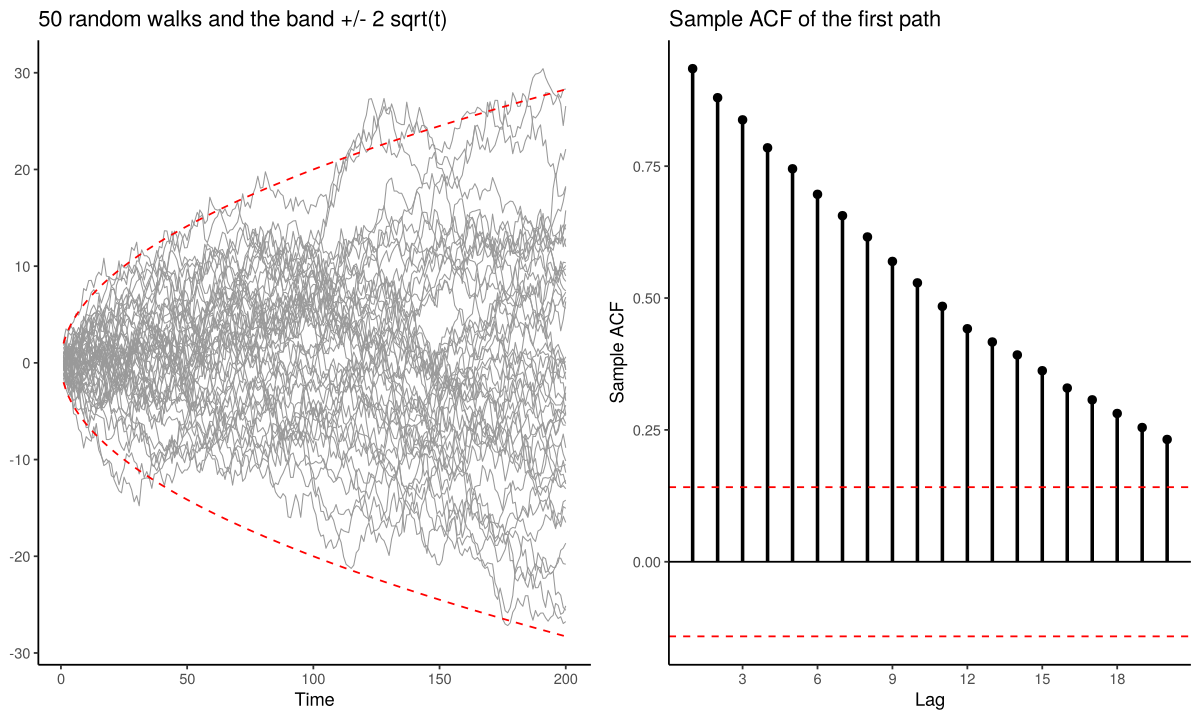

In [3]:
# Random walks: the variance grows with t, and the sample ACF decays slowly
set.seed(123)
T <- 200
paths <- replicate(2000, cumsum(rnorm(T)))                    # T x 2000 matrix
cat("Cross-sectional variance at t = 50, 100, 200:",
    round(apply(paths[c(50, 100, 200), ], 1, var), 1), "  (theory: 50, 100, 200)\n")
cat("Share of paths outside +/- 2 sqrt(t) at t = 200:",
    round(mean(abs(paths[200, ]) > 2 * sqrt(200)), 3), "\n")

df  <- data.frame(time = rep(1:T, 50), value = as.vector(paths[, 1:50]),
                  path = rep(1:50, each = T))
env <- data.frame(time = 1:T, hi = 2 * sqrt(1:T), lo = -2 * sqrt(1:T))
g1 <- ggplot() + theme_classic() +
  geom_line(data = df, aes(time, value, group = path), colour = "grey60", linewidth = 0.3) +
  geom_line(data = env, aes(time, hi), colour = "red", linetype = "dashed") +
  geom_line(data = env, aes(time, lo), colour = "red", linetype = "dashed") +
  labs(x = "Time", y = NULL, title = "50 random walks and the band +/- 2 sqrt(t)")
grid.arrange(g1, sample_acf_plot(paths[, 1], L = 20, title = "Sample ACF of the first path"),
             ncol = 2)

**Reading the output.** The cross-sectional variances (46.8, 88.6 and 191.3) are close to $t\sigma^2=50,\,100,\,200$: the spread of possible paths grows like $\sqrt t$, and 4.1% of the paths lie outside $\pm2\sqrt t$ at $t=200$, close to the 4.6% implied by the normal distribution. Each individual path nevertheless seems to have trends and cycles, none of which is real. The sample ACF of a single path starts at about 0.93 and declines almost linearly, still at 0.23 at lag 20 — the unit-root signature, quite unlike the geometric decay of a stationary AR(1).

# 3&nbsp;&nbsp;Unit roots, integration and ARIMA models

## The unit root

Write an AR($p$) as $\phi(L)Y_t=c+\varepsilon_t$ with $\phi(z)=1-\phi_1z-\cdots-\phi_pz^p$. Lectures 6–8 showed that the process is stationary when all roots of $\phi(z)=0$ lie **outside** the unit circle. A **unit root** is a root at $z=1$, that is

$$
\phi(1)=1-\phi_1-\phi_2-\cdots-\phi_p=0 .
$$

For an AR(1), $(1-\phi L)Y_t=c+\varepsilon_t$, this is simply $\phi=1$: the random walk. (A root at $z=-1$ also lies on the circle, but it generates an oscillation at frequency $\pi$, a seasonal-type unit root; in this lecture "unit root" means $z=1$.)

For an AR(2), factor the polynomial as $\phi(L)=(1-\lambda_1L)(1-\lambda_2L)$, where $\lambda_1,\lambda_2$ are the **inverse** roots. Stationarity requires $|\lambda_1|<1$ and $|\lambda_2|<1$; the process has one unit root when $\lambda_1=1$ and $|\lambda_2|<1$. For example,

$$
Y_t=1.5Y_{t-1}-0.5Y_{t-2}+\varepsilon_t
\quad\Longleftrightarrow\quad
(1-1.5L+0.5L^2)Y_t=(1-L)(1-0.5L)Y_t=\varepsilon_t ,
$$

so $(1-0.5L)\Delta Y_t=\varepsilon_t$: the **difference** is a stationary AR(1). The roots of $1-1.5z+0.5z^2$ are $z=1$ (on the circle) and $z=2$ (outside). With a double unit root, as in $Y_t=2Y_{t-1}-Y_{t-2}+\varepsilon_t$, i.e. $(1-L)^2Y_t=\varepsilon_t$, the series must be differenced twice.

In general, if $\phi(L)$ has a single unit root it factors as $\phi(L)=(1-L)\phi^\ast(L)$, with $\phi^\ast(L)$ of order $p-1$ and all its roots outside the unit circle, and

$$
\Delta Y_t=c+\phi^\ast_1\Delta Y_{t-1}+\cdots+\phi^\ast_{p-1}\Delta Y_{t-p+1}+\varepsilon_t
$$

is a stationary AR($p-1$) in the differences.

## Shocks become permanent

Write the differences in Wold form, $\Delta Y_t=\delta+\psi^\ast(L)\varepsilon_t$ with $\psi^\ast(L)=\beta(L)/\phi^\ast(L)$. The response of the **level** $h$ periods after a unit shock is the cumulated response of the difference,

$$
\frac{\partial Y_{t+h}}{\partial\varepsilon_t}=\sum_{j=0}^{h}\psi^\ast_j
\;\longrightarrow\;
\psi^\ast(1)=\frac{\beta(1)}{\phi^\ast(1)}\qquad(h\to\infty).
$$

The limit $\psi^\ast(1)$ is the **long-run impact** of a shock — Campbell and Mankiw (1987) use it to measure the persistence of output fluctuations. For the AR(2) above, $\psi^\ast(1)=1/(1-0.5)=2$: a unit shock eventually raises $Y$ by two units, permanently. For a stationary process the corresponding limit is zero.

## Integration and ARIMA models

A process that must be differenced $d$ times to become stationary (and invertible) is **integrated of order $d$**, $Y_t\sim I(d)$. Stationary series are $I(0)$; random walks are $I(1)$. If $\Delta^dY_t$ is a stationary ARMA($p,q$), then $Y_t$ is an **ARIMA($p,d,q$)** process:

$$
\phi(L)(1-L)^dY_t=c+\beta(L)\varepsilon_t .
$$

For instance, ARIMA(1,1,0) is $\Delta Y_t=c+\phi\Delta Y_{t-1}+\varepsilon_t$ — the AR(2) example with $c=0$ and $\phi=0.5$. In R, `arima(y, order = c(p, d, q))` differences internally; note that with $d\ge1$ it drops the constant, so a drift must be added as a regressor (`xreg = seq_along(y)`) or the model fitted to `diff(y)`.

### Predict

Compare the stationary AR(2) of Lectures 6–9 ($\phi_1=0.5,\ \phi_2=0.25$) with the unit-root AR(2) above ($\phi_1=1.5,\ \phi_2=-0.5$). Where do the roots lie? What does each impulse response converge to?

Moduli of the roots, stationary AR(2): 1.236 3.236 


Moduli of the roots, unit-root  AR(2): 1 2 


Response after 40 periods:  stationary = 0.000151    unit root = 2 


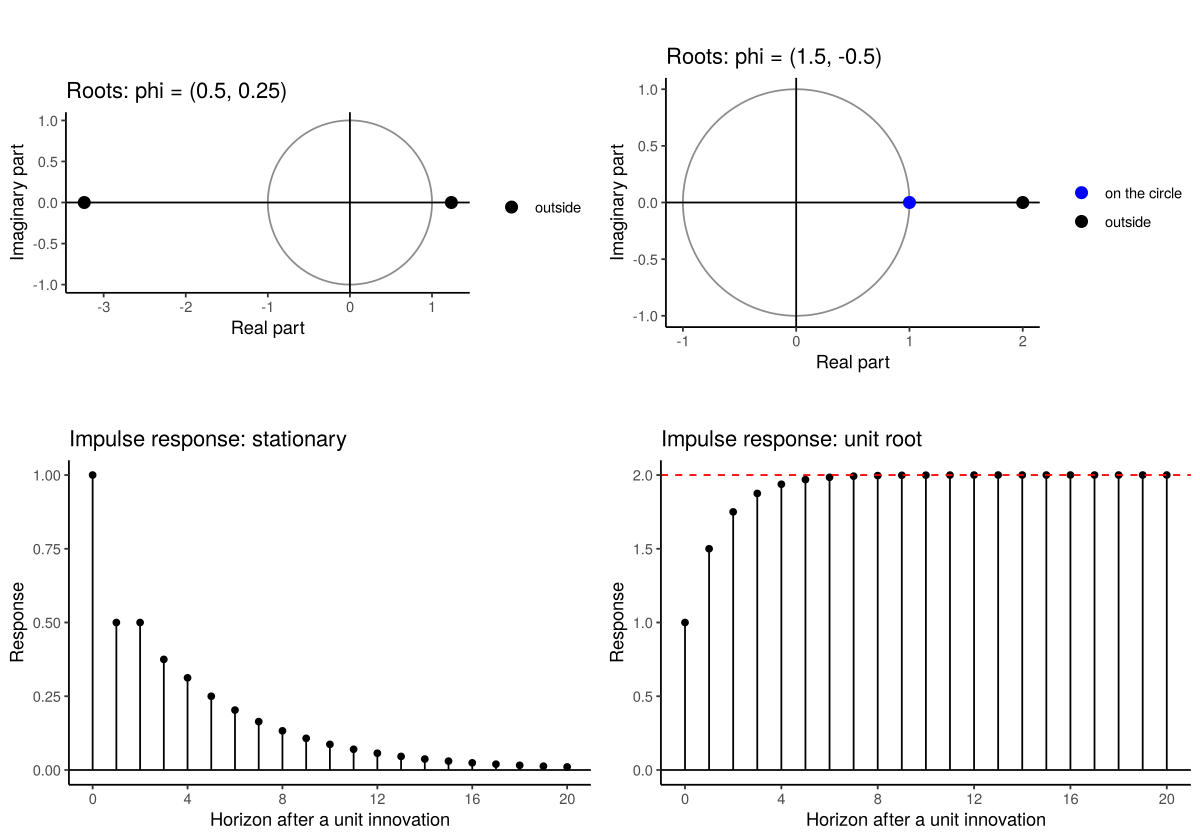

In [4]:
# Roots and impulse responses: stationary AR(2) vs AR(2) with a unit root
ar_stat <- c(0.5, 0.25)    # Lectures 6-9, model A
ar_unit <- c(1.5, -0.5)    # (1 - L)(1 - 0.5L)
cat("Moduli of the roots, stationary AR(2):", round(Mod(polyroot(c(1, -ar_stat))), 3), "\n")
cat("Moduli of the roots, unit-root  AR(2):", round(Mod(polyroot(c(1, -ar_unit))), 3), "\n")
cat("Response after 40 periods:  stationary =", signif(ARMAtoMA(ar = ar_stat, lag.max = 40)[40], 3),
    "   unit root =", round(ARMAtoMA(ar = ar_unit, lag.max = 40)[40], 4), "\n")
options(repr.plot.height = 7)
grid.arrange(
  roots_plot(polyroot(c(1, -ar_stat)), title = "Roots: phi = (0.5, 0.25)"),
  roots_plot(polyroot(c(1, -ar_unit)), title = "Roots: phi = (1.5, -0.5)"),
  irf_plot(ar = ar_stat, h = 20, title = "Impulse response: stationary"),
  irf_plot(ar = ar_unit, h = 20, title = "Impulse response: unit root") +
    geom_hline(yintercept = 2, linetype = "dashed", colour = "red"),
  ncol = 2)
options(repr.plot.height = 6)

**Reading the output.** The stationary AR(2) has both roots outside the unit circle (moduli 1.24 and 3.24), and its impulse response is essentially zero after 40 periods ($1.5\times10^{-4}$). The unit-root AR(2) has one root exactly on the circle (blue) and one at $z=2$; its impulse response rises from 1 to 1.5, 1.75, … and converges to $\psi^\ast(1)=2$ (dashed red line). A shock to a unit-root process is never undone: with a stationary $\phi^\ast(L)$ the level adjusts gradually, but to a permanently different value.

## $I(0)$ versus $I(1)$: a summary

| Property | $I(0)$ | $I(1)$ |
|---|---|---|
| Variance | finite and constant | grows with $t$ |
| Autocorrelations | decay quickly; $\sum_j\lvert\rho_j\rvert<\infty$ | stay close to one, decay slowly |
| Effect of a shock | transitory | permanent |
| Mean reversion | frequent crossings of the mean | expected time between crossings is infinite |
| Long-horizon forecast | converges to the mean (or trend) | the current level plus drift |
| Forecast-error variance | bounded | grows linearly with the horizon |

# 4&nbsp;&nbsp;Detrending or differencing?

## One model that nests the cases

Combine the TS and DS models in the **component form**

$$
Y_t=\mu+\delta t+u_t,\qquad u_t=\phi u_{t-1}+\varepsilon_t .
$$

Substituting $u_t=Y_t-\mu-\delta t$ into the AR(1) gives the reduced form

$$
\boxed{\;Y_t=\underbrace{\mu(1-\phi)+\phi\delta}_{\text{constant}}\;+\;\underbrace{\delta(1-\phi)}_{\text{trend coefficient}}\,t\;+\;\phi Y_{t-1}+\varepsilon_t .\;}
$$

- $|\phi|<1$ and $\delta\neq0$: trend-stationary — a deterministic trend with stationary AR(1) noise.
- $|\phi|<1$ and $\delta=0$: stationary around the mean $\mu$.
- $\phi=1$: the trend coefficient **vanishes** and the constant becomes $\delta$, so $\Delta Y_t=\delta+\varepsilon_t$ — a random walk with drift $\delta$, or a pure random walk if $\delta=0$.

The last point is the key to the Dickey–Fuller $\Phi$ tests of Section 6: under the unit-root null the deterministic terms of the level regression are **restricted**, so it is natural to test those restrictions jointly with $\phi=1$. A random walk whose differences contain a trend, $\Delta Y_t=c+\delta t+\varepsilon_t$, lies outside this component model; its level has a **quadratic** trend (series $Y_6$ in Section 7).

## Removing the trend

If the trend is **stochastic**, differencing removes it: for a random walk with drift, $\Delta Y_t=\delta+\varepsilon_t$ is white noise with mean $\delta$. If the trend is **deterministic**, detrending removes it: regress $Y_t$ on a constant and $t$ and keep the residuals. The wrong transformation is costly in both directions.

**Over-differencing a TS series.** If $Y_t=\mu+\delta t+\varepsilon_t$, then

$$
\Delta Y_t=\delta+\varepsilon_t-\varepsilon_{t-1},
$$

an MA(1) with coefficient $-1$: a **unit root in the MA polynomial**. The series is stationary but not invertible, its first autocorrelation is $-0.5$, and its PACF decays only slowly. Similarly, differencing a stationary AR(1), $Y_t=\phi Y_{t-1}+\varepsilon_t$, gives the ARMA(1,1) $\Delta Y_t=\phi\Delta Y_{t-1}+\varepsilon_t-\varepsilon_{t-1}$: unnecessary structure that complicates identification and harms forecasts.

**Detrending a DS series.** Regressing a random walk on time does not remove its stochastic trend. The residuals remain $I(1)$ and display long spurious "cycles" that are an artefact of the procedure (Nelson and Kang 1981). Any business-cycle measure obtained in this way is suspect.

### Predict before you simulate

For a TS series with white-noise errors ($\delta=0.2$, $T=500$), what will the sample ACF of $\Delta y_t$ show at lag 1? What will the ACF of the detrended series look like? For a random walk with drift 0.5, what will the ACFs of the differenced and of the detrended series look like?

Lag-1 sample autocorrelation:  differenced = -0.499    detrended = -0.055 


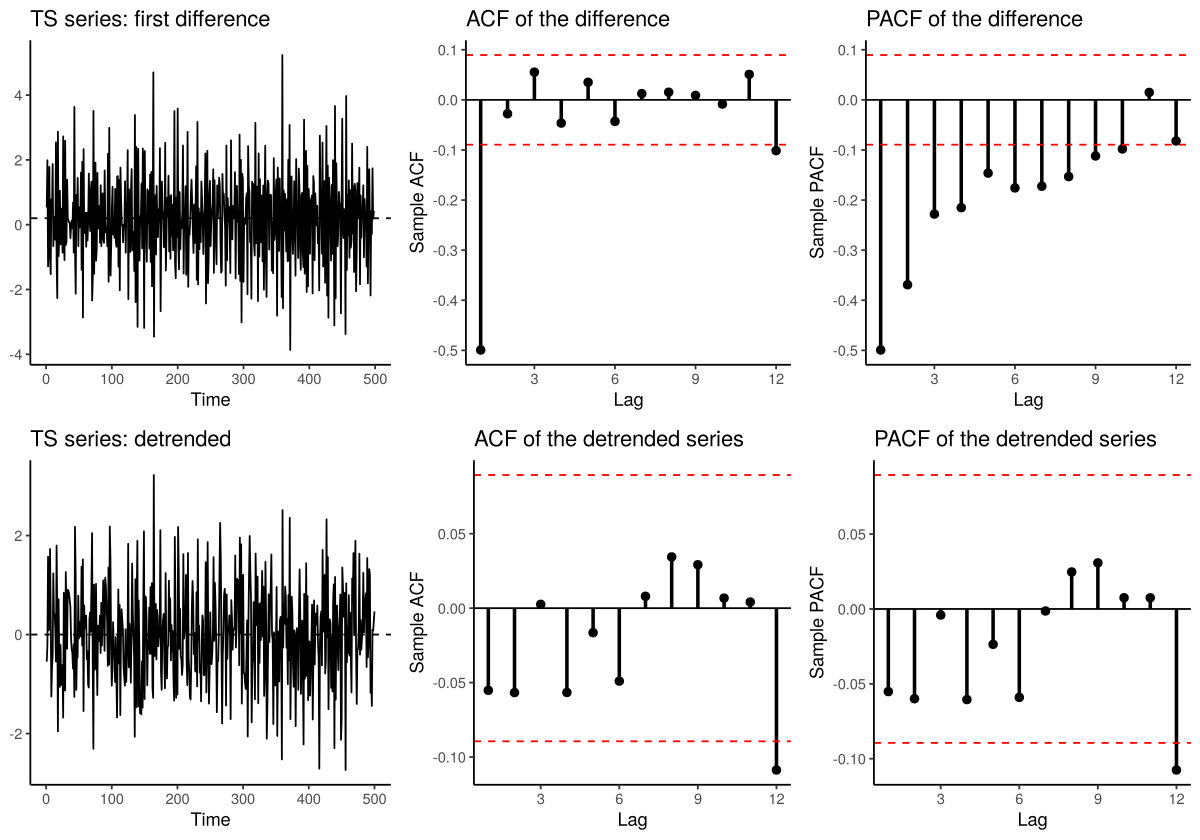

In [5]:
# Differencing vs detrending a trend-stationary series (white-noise errors)
set.seed(123)
T  <- 500; tt <- 1:T
y7   <- 0.8 + 0.2 * tt + rnorm(T)
dy7  <- diff(y7)                       # over-differenced: MA(1) with coefficient -1
d1y7 <- residuals(lm(y7 ~ tt))         # detrended: white noise
cat("Lag-1 sample autocorrelation:  differenced =", round(acf(dy7, plot = FALSE)$acf[2], 3),
    "   detrended =", round(acf(d1y7, plot = FALSE)$acf[2], 3), "\n")
options(repr.plot.height = 7)
grid.arrange(ts_plot(dy7, mu = 0.2, title = "TS series: first difference"),
             sample_acf_plot(dy7,  L = 12, title = "ACF of the difference"),
             sample_pacf_plot(dy7, L = 12, title = "PACF of the difference"),
             ts_plot(d1y7, mu = 0, title = "TS series: detrended"),
             sample_acf_plot(d1y7,  L = 12, title = "ACF of the detrended series"),
             sample_pacf_plot(d1y7, L = 12, title = "PACF of the detrended series"),
             ncol = 3)
options(repr.plot.height = 6)

Lag-1 sample autocorrelation:  differenced = -0.055    detrended = 0.963 


Crossings of zero by the detrended series: 28 in 500 periods


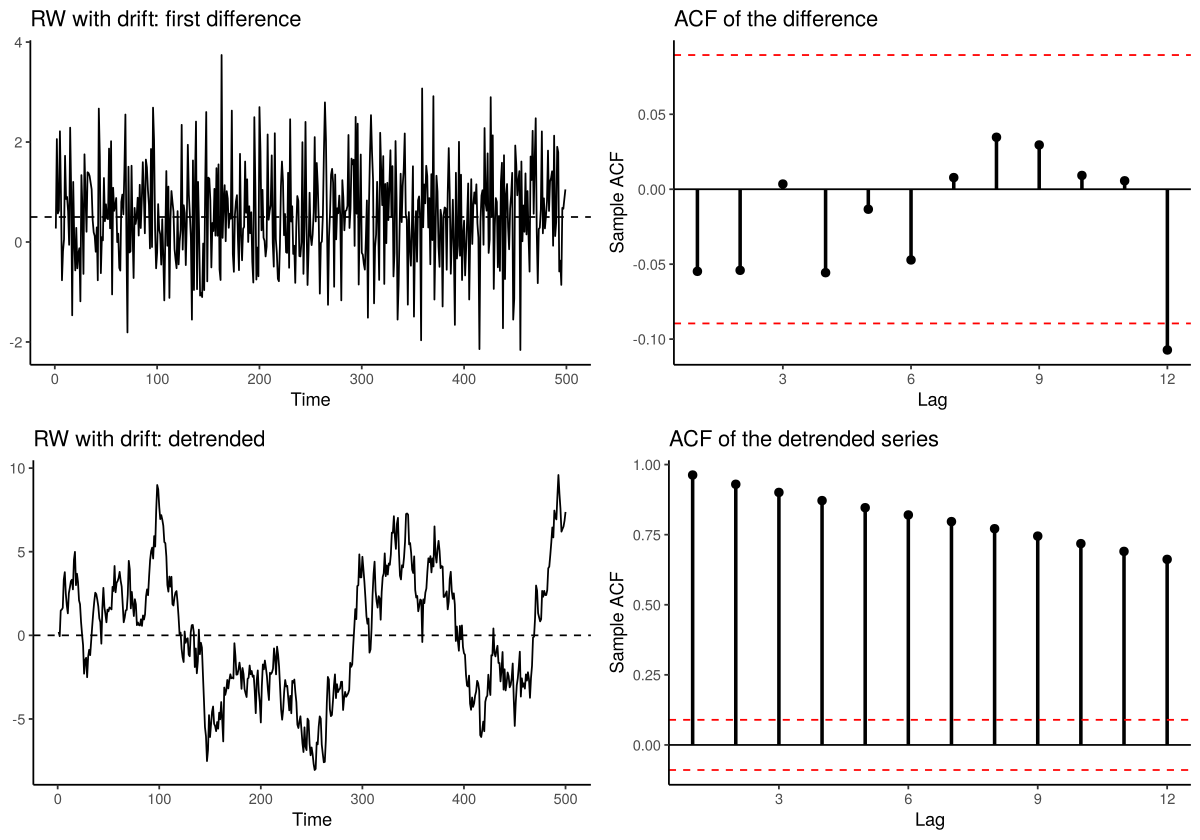

In [6]:
# Differencing vs detrending a random walk with drift 0.5
set.seed(123)
y5 <- e <- rnorm(T)
for (t in 2:T) y5[t] <- 0.5 + y5[t - 1] + e[t]
dy5  <- diff(y5)                       # white noise with mean 0.5
d1y5 <- residuals(lm(y5 ~ tt))         # still I(1)
cat("Lag-1 sample autocorrelation:  differenced =", round(acf(dy5, plot = FALSE)$acf[2], 3),
    "   detrended =", round(acf(d1y5, plot = FALSE)$acf[2], 3), "\n")
cat("Crossings of zero by the detrended series:", sum(diff(sign(d1y5)) != 0), "in", T, "periods\n")
options(repr.plot.height = 7)
grid.arrange(ts_plot(dy5, mu = 0.5, title = "RW with drift: first difference"),
             sample_acf_plot(dy5, L = 12, title = "ACF of the difference"),
             ts_plot(d1y5, mu = 0, title = "RW with drift: detrended"),
             sample_acf_plot(d1y5, L = 12, title = "ACF of the detrended series"),
             ncol = 2)
options(repr.plot.height = 6)

**Reading the output.** *Trend-stationary series.* The first difference has a lag-1 autocorrelation of $-0.499$ — the $-0.5$ of a non-invertible MA(1) — and nothing significant beyond it, while its PACF is negative and decays slowly ($-0.50,\,-0.37,\,-0.23,\,\dots$), the fingerprint of an MA root on the unit circle. A modeller who differenced this series would be led to an MA(1) with $\hat\beta\approx-1$. The detrended series is white noise: its autocorrelations lie inside the bands, apart from lag 12, which just crosses — the kind of isolated long lag Lecture 9 warned us not to chase.

*Random walk with drift.* The first difference is white noise around 0.5 (lag-1 autocorrelation $-0.055$). The detrended series is not: its lag-1 autocorrelation is 0.963, its ACF decays slowly, and it crosses zero only 28 times in 500 periods. Its long swings look like business cycles but are an artefact of detrending a stochastic trend. (Both experiments use the same shocks, so the differenced random walk and the detrended TS series have identical correlograms: each is just the original white noise.)

# 5&nbsp;&nbsp;Why standard inference fails under a unit root

Take the simplest case, $Y_t=\phi Y_{t-1}+\varepsilon_t$ with $Y_0=0$, and the OLS estimator

$$
\hat\phi=\frac{\sum_{t=2}^{T}Y_tY_{t-1}}{\sum_{t=2}^{T}Y_{t-1}^2}.
$$

When $|\phi|<1$, Lecture 9 showed that $\sqrt T(\hat\phi-\phi)\overset{d}{\to}N(0,\,1-\phi^2)$. At $\phi=1$ that variance is zero, a first hint that something changes. Because $\operatorname{Var}(Y_t)=t\sigma^2$, the denominator $\sum Y_{t-1}^2$ grows like $T^2$ rather than $T$, and (Phillips 1987)

$$
T(\hat\phi-1)\;\Rightarrow\;\frac{\tfrac12\{W(1)^2-1\}}{\int_0^1W(r)^2\,dr},
\qquad
\tau=\frac{\hat\phi-1}{\operatorname{SE}(\hat\phi)}\;\Rightarrow\;\frac{\tfrac12\{W(1)^2-1\}}{\big\{\int_0^1W(r)^2\,dr\big\}^{1/2}},
$$

where $W(r)$ is a standard Brownian motion, the continuous-time limit of a scaled random walk. Four consequences follow.

1. **Superconsistency.** $\hat\phi$ converges at rate $T$, not $\sqrt T$.
2. **Non-normal, skewed limits.** $W(1)^2\sim\chi^2(1)$ and $P\{\chi^2(1)<1\}\approx0.68$, so about two-thirds of the estimates fall **below** one even though $\phi=1$. OLS is biased downwards (the bias of Lecture 9, now at its worst), and the distribution of $\tau$ lies to the left of $N(0,1)$.
3. **Deterministic terms matter.** With a constant (or a constant and trend) in the regression, $W$ is replaced by a demeaned (detrended) Brownian motion and the distribution moves further left. Each specification needs its own critical values.
4. **Critical values come from simulation.** The limits have no closed form. Dickey and Fuller (1979) and Fuller (1976) tabulated them by Monte Carlo; MacKinnon (1996) fitted response surfaces that give critical values and $p$-values for any $T$.


### Predict before you simulate

We simulate 20,000 random walks with $T=100$ and compute $\tau$ from three regressions: no deterministic terms, a constant, and a constant and trend. Where will the 5% quantiles lie relative to the normal value $-1.645$? If you used $-1.645$ with the trend regression, how often would you wrongly reject a true unit root?

Quantiles of tau under H0   (N(0,1): 1% -2.33, 5% -1.645, 10% -1.28)


     none constant trend
1%  -2.64    -3.52 -4.08
5%  -1.97    -2.90 -3.47
10% -1.62    -2.60 -3.16
50% -0.49    -1.56 -2.18



Share of phi_hat below 1: 0.680      Mean of phi_hat: 0.9823


Rejection rate of a TRUE unit root using -1.645 with the trend regression: 0.769


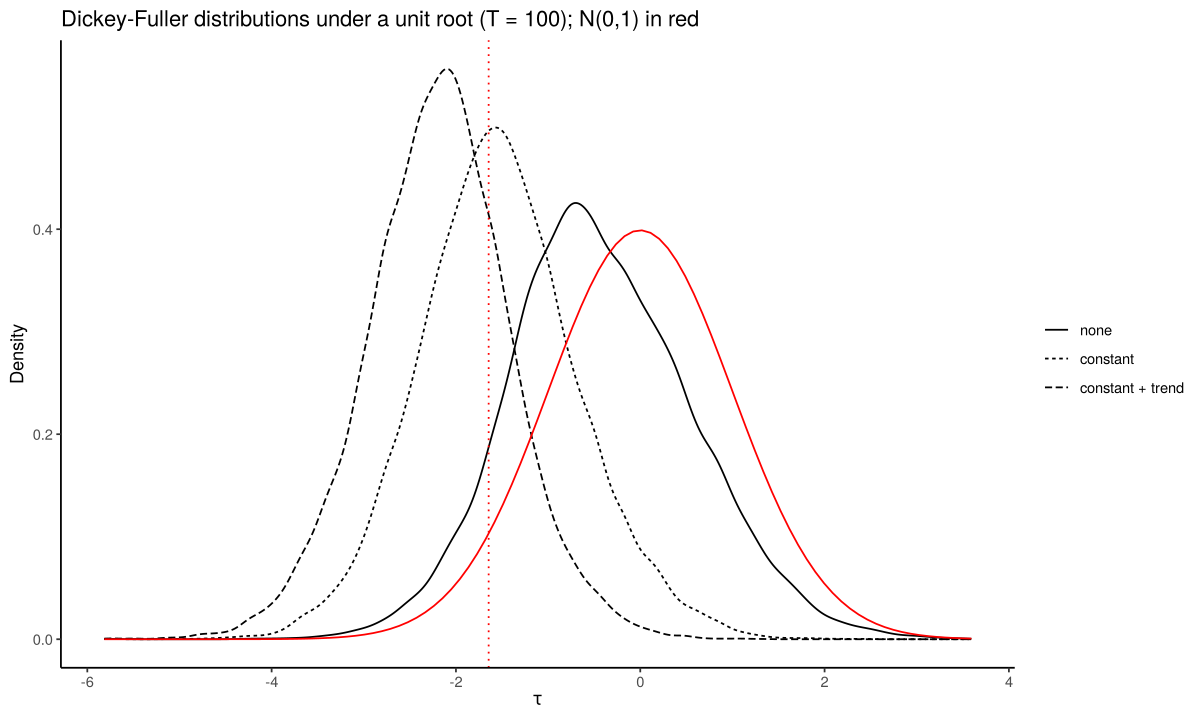

In [7]:
# Dickey-Fuller distributions under H0 (a random walk), T = 100
set.seed(123)
R <- 20000; T <- 100
sims <- t(replicate(R, {
  y  <- cumsum(rnorm(T))
  yl <- head(y, -1)
  c(none = df_tau(y, "none"), constant = df_tau(y, "drift"), trend = df_tau(y, "trend"),
    phi_hat = sum(yl * y[-1]) / sum(yl^2))
}))
cat("Quantiles of tau under H0   (N(0,1): 1% -2.33, 5% -1.645, 10% -1.28)\n")
print(round(apply(sims[, 1:3], 2, quantile, c(0.01, 0.05, 0.10, 0.50)), 2))
cat(sprintf("\nShare of phi_hat below 1: %.3f      Mean of phi_hat: %.4f\n",
            mean(sims[, "phi_hat"] < 1), mean(sims[, "phi_hat"])))
cat(sprintf("Rejection rate of a TRUE unit root using -1.645 with the trend regression: %.3f\n",
            mean(sims[, "trend"] < -1.645)))

dens <- data.frame(tau = as.vector(sims[, 1:3]),
                   regression = factor(rep(c("none", "constant", "constant + trend"), each = R),
                                       levels = c("none", "constant", "constant + trend")))
ggplot(dens, aes(tau, linetype = regression)) + theme_classic() +
  geom_density(key_glyph = "path") +
  stat_function(fun = dnorm, colour = "red", inherit.aes = FALSE) +
  geom_vline(xintercept = -1.645, colour = "red", linetype = "dotted") +
  labs(x = expression(tau), y = "Density", linetype = NULL,
       title = "Dickey-Fuller distributions under a unit root (T = 100); N(0,1) in red")

**Reading the output.** The simulated quantiles reproduce the Dickey–Fuller tables: the 5% points are $-1.97$, $-2.90$ and $-3.47$ for the three regressions (tabulated for $T=100$: $-1.95$, $-2.89$, $-3.45$). All lie well to the left of $-1.645$, and each deterministic term moves the distribution further left, as the density plot shows. 68.0% of the estimates $\hat\phi$ fall below one, as $P\{\chi^2(1)<1\}=0.68$ predicts, and their mean is 0.982 rather than 1. Using the normal critical value with the trend regression would reject a true unit root in 77% of samples.

# 6&nbsp;&nbsp;Dickey–Fuller and augmented Dickey–Fuller tests

## The Dickey–Fuller regressions

Subtract $Y_{t-1}$ from both sides of the AR(1): $\Delta Y_t=\gamma Y_{t-1}+\varepsilon_t$ with $\gamma=\phi-1$. Testing $H_0:\phi=1$ against $H_1:\phi<1$ is the same as testing $H_0:\gamma=0$ against $H_1:\gamma<0$. The $t$-ratio $\hat\gamma/\operatorname{SE}(\hat\gamma)$ — numerically identical to $(\hat\phi-1)/\operatorname{SE}(\hat\phi)$ — is compared with Dickey–Fuller critical values, not normal ones. Three regressions differ in their deterministic terms:

$$
\begin{aligned}
&\text{none:}  && \Delta Y_t=\gamma Y_{t-1}+\varepsilon_t\\
&\text{drift:} && \Delta Y_t=c+\gamma Y_{t-1}+\varepsilon_t\\
&\text{trend:} && \Delta Y_t=c+\delta t+\gamma Y_{t-1}+\varepsilon_t
\end{aligned}
$$

Dickey and Fuller (1981) added $F$-type statistics for **joint** hypotheses on the deterministic terms and $\gamma$,

$$
\Phi=\frac{(\text{RSS}_R-\text{RSS}_U)/r}{\text{RSS}_U/(T-k)},
$$

where $\text{RSS}_R$ and $\text{RSS}_U$ are the restricted and unrestricted residual sums of squares, $r$ is the number of restrictions, $T$ the number of observations and $k$ the number of parameters in the unrestricted regression. The $\Phi$ statistics look like ordinary $F$ statistics but have **non-standard** distributions and their own critical values.

| Regression | $H_0$ | Statistic (urca name) | 5% c.v., $T=100$ | 5% c.v., $T=500$ |
|---|---|---|---|---|
| trend | $\gamma=0$ | $\tau_\tau$ (`tau3`) | $-3.45$ | $-3.42$ |
| | $\delta=\gamma=0$ | $\Phi_3$ (`phi3`) | $6.49$ | $6.30$ |
| | $c=\delta=\gamma=0$ | $\Phi_2$ (`phi2`) | $4.88$ | $4.71$ |
| drift | $\gamma=0$ | $\tau_\mu$ (`tau2`) | $-2.89$ | $-2.87$ |
| | $c=\gamma=0$ | $\Phi_1$ (`phi1`) | $4.71$ | $4.61$ |
| none | $\gamma=0$ | $\tau$ (`tau1`) | $-1.95$ | $-1.95$ |

Compare the one-sided 5% normal value, $-1.645$: the $\tau$ critical values are much more negative, and they move further left as deterministic terms are added.

## Choosing the deterministic terms: think about $H_1$ as well as $H_0$

Each regression pairs a null with an alternative, and the pair should match what the data could plausibly be (Hamilton 1994, Section 17.4; Elder and Kennedy 2001). Using the component form of Section 4:

| Regression | Under $H_0$ ($\gamma=0$) the series is… | Under $H_1$ ($\gamma<0$) the series is… | Use when the data… |
|---|---|---|---|
| none | a random walk without drift | a zero-mean stationary AR | fluctuate around zero |
| drift | a random walk without drift ($c=\mu(1-\phi)=0$) | stationary around a nonzero mean | show no trend but a nonzero level |
| trend | a random walk with drift | trend-stationary | trend |

Two rules follow.

- **Omitting a deterministic term that is present makes the test inconsistent.** A trend-stationary series tested with the drift regression will almost never reject, however large $T$ is, because the alternative cannot describe a trend.
- **Including a term that is absent costs power.** Each extra deterministic term moves the critical value to the left, so a stationary but persistent series becomes harder to distinguish from a unit root.

For a trending series, start with the trend regression: under the alternative only it describes the data.

## The augmented Dickey–Fuller test

If the errors are autocorrelated, the DF statistics have the wrong null distribution. Any AR($p$) can be reparameterized as

$$
\Delta Y_t=c+\gamma Y_{t-1}+\sum_{i=1}^{p-1}\alpha_i\,\Delta Y_{t-i}+\varepsilon_t,
\qquad
\gamma=-\phi(1)=\phi_1+\cdots+\phi_p-1,
\qquad
\alpha_i=-\sum_{j=i+1}^{p}\phi_j ,
$$

so a unit root, $\phi(1)=0$, is again $\gamma=0$. For an AR(3), for example,

$$
\Delta Y_t=(\phi_1+\phi_2+\phi_3-1)Y_{t-1}-(\phi_2+\phi_3)\Delta Y_{t-1}-\phi_3\Delta Y_{t-2}+\varepsilon_t .
$$

The **augmented Dickey–Fuller (ADF)** regression adds lagged differences to the chosen deterministic specification,

$$
\Delta Y_t=c+\delta t+\gamma Y_{t-1}+\sum_{i=1}^{p}\alpha_i\,\Delta Y_{t-i}+\varepsilon_t ,
$$

and $\tau$ and $\Phi$ keep **the same** critical values. With ARMA errors, the invertible MA part is an AR($\infty$); Said and Dickey (1984) showed that the ADF test remains valid if $p$ grows with $T$, but no faster than $T^{1/3}$.

**Choosing $p$.**

- Set a maximum, for example Schwert's (1989) rule $p_{\max}=\lfloor12(T/100)^{1/4}\rfloor$.
- Then either go *general-to-specific* — drop the last lag while it is insignificant (Ng and Perron 1995) — or minimize AIC or BIC over $p\le p_{\max}$ on a common sample.
- Check that the residuals are white noise with the Ljung–Box test of Lecture 9.

Too few lags leave autocorrelation and distort the size; too many waste degrees of freedom and reduce power.

**More than one unit root.** If $I(2)$ is possible, test from the top down (Dickey and Pantula 1987): first test for a unit root in $\Delta Y_t$,

$$
\Delta^2Y_t=c+\gamma\,\Delta Y_{t-1}+\sum_{i=1}^{p}\alpha_i\,\Delta^2Y_{t-i}+\varepsilon_t ,
$$

and only if that is rejected test $Y_t$ itself. $I(2)$ behaviour is rare in economics, but nominal price levels and money stocks are sometimes candidates.


# 7&nbsp;&nbsp;A testing strategy, worked on six simulated series

## The sequential procedure

The true deterministic terms are unknown, and both omitting and including them have costs. The standard response is a sequential procedure (Dolado, Jenkinson and Sosvilla-Rivero 1990; Enders 2015, Ch. 4) that starts from the most general plausible model and simplifies only when the data allow it:

1. **Trend regression.** Estimate $\Delta Y_t=c+\delta t+\gamma Y_{t-1}+\sum\alpha_i\Delta Y_{t-i}+\varepsilon_t$ and test $\gamma=0$ with $\tau_\tau$. If it is rejected, $Y_t$ is (trend-)stationary: stop. Ordinary $t$-tests on $c$ and $\delta$ are now valid.
2. **Is the trend needed?** If $\tau_\tau$ does not reject, test $\delta=\gamma=0$ with $\Phi_3$. If $\Phi_3$ rejects, the trend belongs in the model; test $\gamma=0$ again, now with the **standard normal** distribution (when the data generating process contains a trend, the $t$-ratio is asymptotically normal; West 1988). If $\gamma=0$ is still not rejected, $Y_t$ has a unit root and a trend in its differences: stop.
3. **Drift regression.** If $\Phi_3$ does not reject, drop the trend, estimate $\Delta Y_t=c+\gamma Y_{t-1}+\cdots$ and test with $\tau_\mu$. If it rejects, $Y_t$ is stationary around a mean: stop.
4. **Is the drift needed?** If $\tau_\mu$ does not reject, test $c=\gamma=0$ with $\Phi_1$. If $\Phi_1$ rejects, the drift belongs in the model; test $\gamma=0$ with the standard normal. Non-rejection means a random walk with drift: stop.
5. **No deterministic terms.** If $\Phi_1$ does not reject, estimate $\Delta Y_t=\gamma Y_{t-1}+\cdots$ and test with $\tau$. Non-rejection means a random walk without drift.
6. **Confirm the order of integration** by testing $\Delta Y_t$ in the same way. Rejecting a unit root in $\Delta Y_t$ confirms $Y_t\sim I(1)$.

You will rarely need every step. A plot often shows whether a trend is plausible, and economic knowledge — does the series grow? — can replace a low-powered pre-test (Elder and Kennedy 2001). Understanding *why* each step is there, by asking what the series would look like under $H_0$ and under $H_1$, matters more than following the chart mechanically.

## Six data generating processes

All six series have $T=500$ and are drawn with `set.seed(123)`. $Y_1$–$Y_3$ share one set of AR(1) shocks and $Y_4$–$Y_6$ share another, so within each group the differences come only from the deterministic terms and the unit root. $Y_2$ and $Y_3$ are simulated in component form; the third column gives the implied DF regression (Section 4).

| Series | Simulated as | Implied DF regression | Class |
|---|---|---|---|
| $Y_1$ | $Y_t=0.8Y_{t-1}+\varepsilon_t$ | $\Delta Y_t=-0.2Y_{t-1}+\varepsilon_t$ | $I(0)$, mean 0 |
| $Y_2$ | $Y_t=2+u_t$, $\;u_t=0.8u_{t-1}+\varepsilon_t$ | $\Delta Y_t=0.4-0.2Y_{t-1}+\varepsilon_t$ | $I(0)$, mean 2 |
| $Y_3$ | $Y_t=0.8+0.2t+u_t$ | $\Delta Y_t=0.32+0.04t-0.2Y_{t-1}+\varepsilon_t$ | trend-stationary |
| $Y_4$ | $Y_t=Y_{t-1}+\varepsilon_t$ | $\Delta Y_t=\varepsilon_t$ | $I(1)$, pure random walk |
| $Y_5$ | $Y_t=0.5+Y_{t-1}+\varepsilon_t$ | $\Delta Y_t=0.5+\varepsilon_t$ | $I(1)$ with drift |
| $Y_6$ | $Y_t=0.5+0.2t+Y_{t-1}+\varepsilon_t$ | $\Delta Y_t=0.5+0.2t+\varepsilon_t$ | $I(1)$; $\Delta Y_t$ trend-stationary |

### Predict before you simulate

Before running any test: from the plots below, which DF regression would you start with for each series, and which series do you expect to reject the unit-root null?

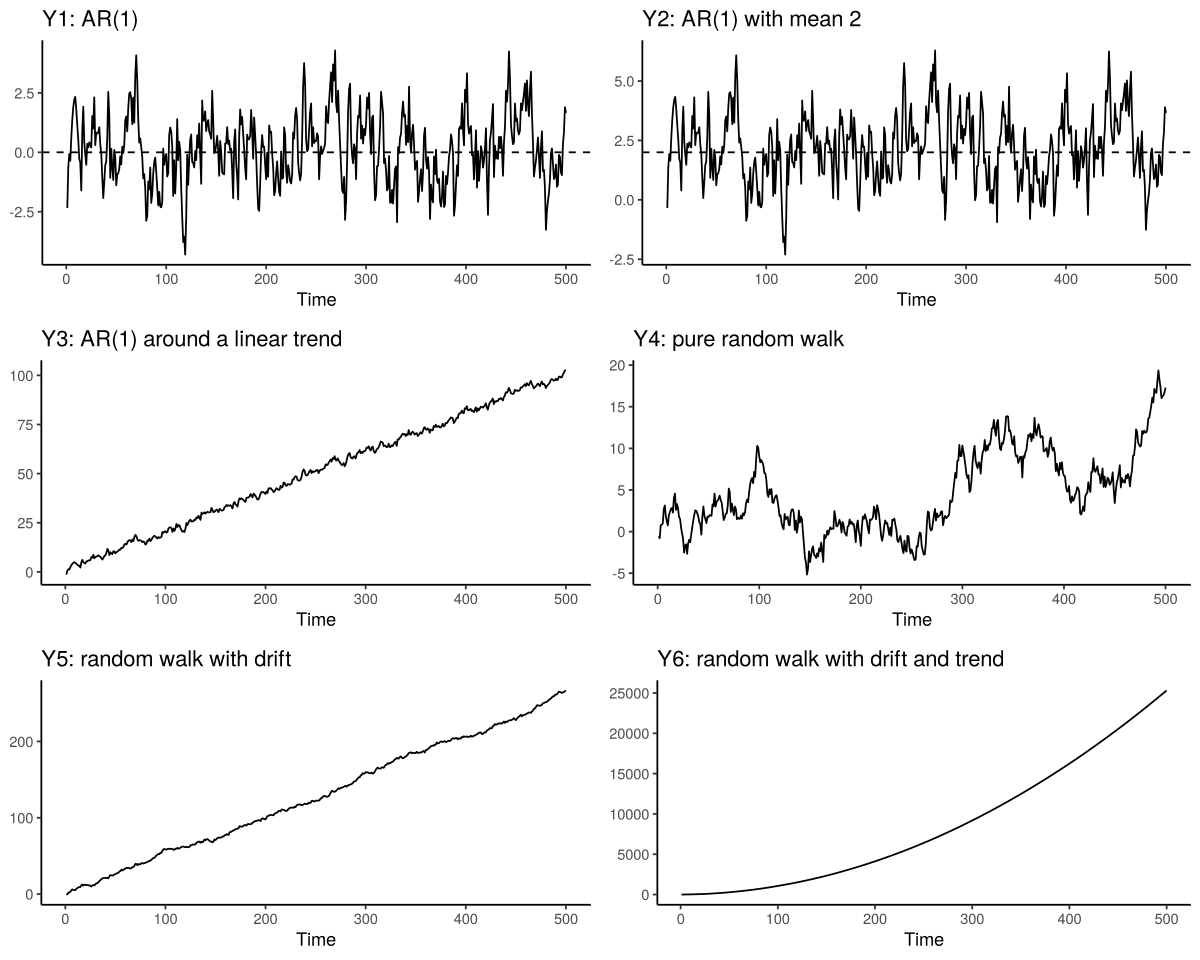

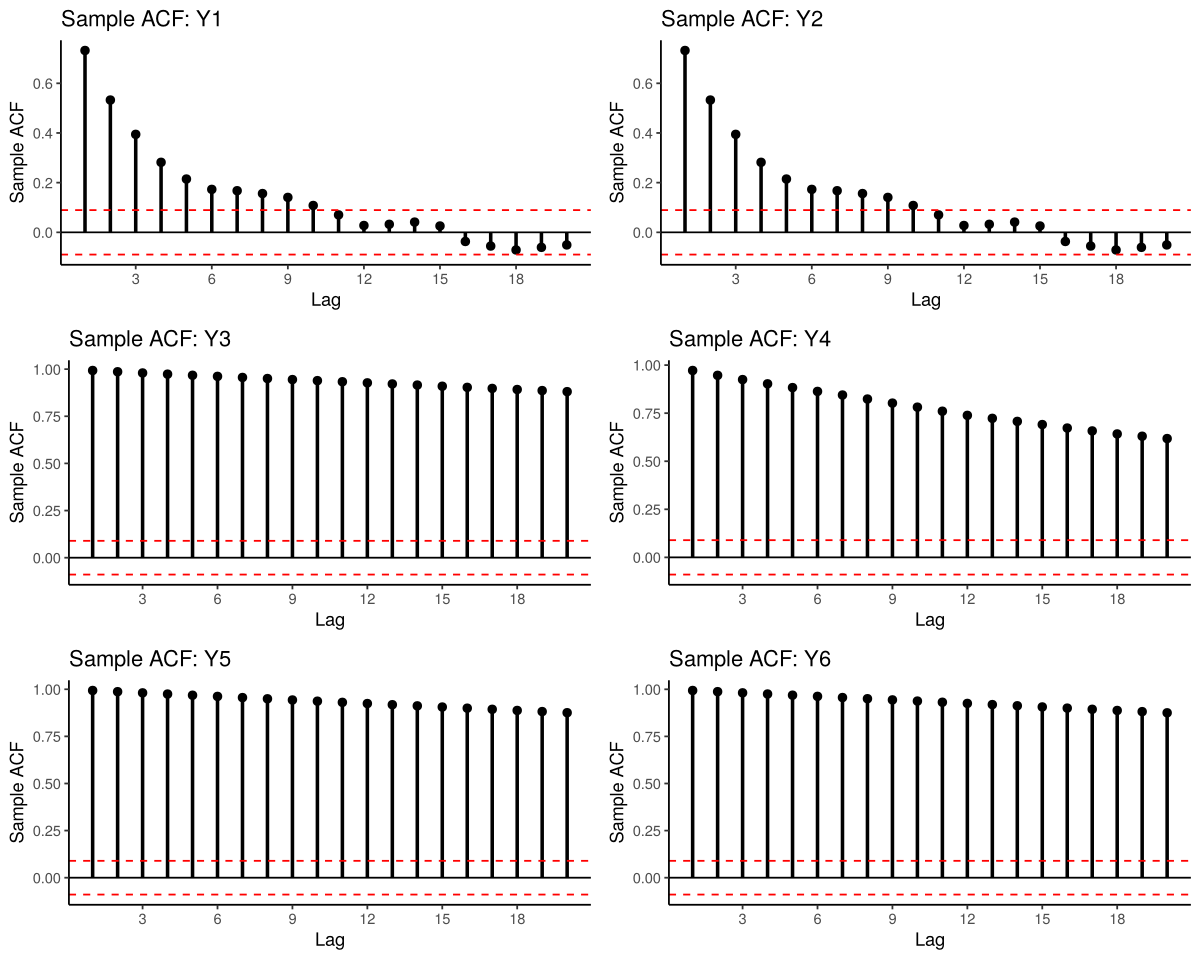

In [9]:
# The six series of the testing strategy (T = 500)
T  <- 500; tt <- 1:T
set.seed(123); y1 <- as.numeric(arima.sim(model = list(ar = 0.8), n = T))
set.seed(123); y2 <- 2 + as.numeric(arima.sim(model = list(ar = 0.8), n = T))
set.seed(123); y3 <- 0.8 + 0.2 * tt + as.numeric(arima.sim(model = list(ar = 0.8), n = T))
set.seed(123); e  <- rnorm(T)
y4 <- y5 <- y6 <- e
for (t in 2:T) {
  y4[t] <- y4[t - 1] + e[t]                        # pure random walk
  y5[t] <- 0.5 + y5[t - 1] + e[t]                  # random walk with drift
  y6[t] <- 0.5 + 0.2 * t + y6[t - 1] + e[t]        # random walk, drift and trend
}
options(repr.plot.height = 8)
grid.arrange(ts_plot(y1, mu = 0, title = "Y1: AR(1)"),
             ts_plot(y2, mu = 2, title = "Y2: AR(1) with mean 2"),
             ts_plot(y3, title = "Y3: AR(1) around a linear trend"),
             ts_plot(y4, title = "Y4: pure random walk"),
             ts_plot(y5, title = "Y5: random walk with drift"),
             ts_plot(y6, title = "Y6: random walk with drift and trend"), ncol = 2)
grid.arrange(sample_acf_plot(y1, title = "Sample ACF: Y1"), sample_acf_plot(y2, title = "Sample ACF: Y2"),
             sample_acf_plot(y3, title = "Sample ACF: Y3"), sample_acf_plot(y4, title = "Sample ACF: Y4"),
             sample_acf_plot(y5, title = "Sample ACF: Y5"), sample_acf_plot(y6, title = "Sample ACF: Y6"),
             ncol = 2)
options(repr.plot.height = 6)

**Reading the graphs.** $Y_1$ and $Y_2$ are the same series shifted by 2: both fluctuate around a fixed level, cross it often, and have geometrically decaying ACFs. $Y_3$ and $Y_5$ both rise steadily and look much alike, yet one is trend-stationary and the other a random walk with drift; both ACFs decay slowly. $Y_4$ wanders with no tendency to return anywhere. $Y_6$ curves upwards — its level grows quadratically — and its ACF also decays slowly. The correlograms separate $Y_1$ and $Y_2$ from the rest but **cannot** separate a deterministic from a stochastic trend. That is the job of the tests.

## Case 1: three stationary series

The plots suggest a regression with no deterministic terms for $Y_1$ (it fluctuates around zero), a constant for $Y_2$ (a nonzero level, no trend) and a constant and trend for $Y_3$. All three use DF regressions without lags, because the series are AR(1); everything carries over to ADF.

In [10]:
# Stationary cases: start from the regression that matches each plot
r1 <- df_report(y1, type = "none",  label = "Y1"); cat("\n")
r2 <- df_report(y2, type = "drift", label = "Y2"); cat("\n")
r3 <- df_report(y3, type = "trend", label = "Y3")
cat(sprintf("\nImplied mean of Y2,  -c/gamma          = %.2f   (true 2)\n",
            -r2$coef["c", 1] / r2$coef["gamma", 1]))
cat(sprintf("Implied slope of Y3, -delta/gamma      = %.3f  (true 0.2)\n",
            -r3$coef["delta (trend)", 1] / r3$coef["gamma", 1]))

Y1 - DF regression: type = "none", 0 lagged difference(s), 499 observations
      Estimate Std. Error t value
gamma  -0.2632    0.03021  -8.713

    statistic cv_5pct p_value        H0  decision
tau    -8.713   -1.95       0 gamma = 0 reject H0


Y2 - DF regression: type = "drift", 0 lagged difference(s), 499 observations
      Estimate Std. Error t value
c       0.5758    0.07775   7.406
gamma  -0.2661    0.03034  -8.769

       statistic cv_5pct p_value            H0  decision
tau_mu    -8.769   -2.87       0     gamma = 0 reject H0
Phi1      38.467    4.61      NA c = gamma = 0 reject H0


Y3 - DF regression: type = "trend", 0 lagged difference(s), 499 observations
              Estimate Std. Error t value
c               0.4428   0.090160   4.911
gamma          -0.2662   0.030380  -8.762
delta (trend)   0.0533   0.006093   8.748

        statistic cv_5pct p_value                    H0  decision
tau_tau    -8.762   -3.42       0             gamma = 0 reject H0
Phi2       33.367    4.71      NA c = delta = gamma = 0 reject H0
Phi3       38.393    6.30      NA     delta = gamma = 0 reject H0



Implied mean of Y2,  -c/gamma          = 2.16   (true 2)


Implied slope of Y3, -delta/gamma      = 0.200  (true 0.2)


**Reading the output.** 
- **$Y_1$.** $\hat\gamma=-0.26$, so $\hat\phi=\hat\gamma+1=0.74$. $\tau=-8.71$ is far below the 5% critical value $-1.95$: reject the unit root. $Y_1$ is $I(0)$, with neither a deterministic nor a stochastic trend.
- **$Y_2$.** $\tau_\mu=-8.77<-2.87$: reject. Because $Y_2$ is $I(0)$, the ordinary $t$-ratio on the constant (7.41) is valid, and the constant is clearly nonzero; $\Phi_1$ is irrelevant once the unit root has been rejected. The implied mean, $-\hat c/\hat\gamma=2.16$, is close to the true value 2.
- **$Y_3$.** $\tau_\tau=-8.76<-3.42$: reject. With the unit root rejected, the trend's ordinary $t$-ratio (8.75) is valid, and $Y_3$ is trend-stationary. The estimated trend coefficient, 0.053, is not the slope of the series but $\delta(1-\phi)$ (Section 4); dividing by $-\hat\gamma$ recovers the slope, 0.200.

The three estimates of $\gamma$ are almost identical ($-0.263$, $-0.266$, $-0.266$): the series share the same shocks, and correctly specified deterministic terms leave the estimate of persistence unchanged.

## Case 2: a pure random walk ($Y_4$)

$Y_4$ shows no trend. Pretending that we do not know how it was generated, it could be a random walk or a stationary series with a nonzero mean, so we start with the drift regression. If the drift turns out to be unnecessary, we re-test without it, and finally test the difference.

In [11]:
# Y4: drift regression -> Phi1 -> regression without constant -> test the difference
r4  <- df_report(y4, type = "drift", label = "Y4"); cat("\n")
r4a <- df_report(y4, type = "none",  label = "Y4"); cat("\n")
r4b <- df_report(diff(y4), type = "none", label = "diff(Y4)")

Y4 - DF regression: type = "drift", 0 lagged difference(s), 499 observations
      Estimate Std. Error t value
c      0.10130    0.05972   1.695
gamma -0.01438    0.00899  -1.600

       statistic cv_5pct p_value            H0      decision
tau_mu    -1.600   -2.87  0.4818     gamma = 0 do not reject
Phi1       1.618    4.61      NA c = gamma = 0 do not reject


Y4 - DF regression: type = "none", 0 lagged difference(s), 499 observations
       Estimate Std. Error t value
gamma -0.003942   0.006561 -0.6009

    statistic cv_5pct p_value        H0      decision
tau    -0.601   -1.95  0.4568 gamma = 0 do not reject


diff(Y4) - DF regression: type = "none", 0 lagged difference(s), 498 observations
      Estimate Std. Error t value
gamma   -1.053     0.0448  -23.51

    statistic cv_5pct p_value        H0  decision
tau   -23.512   -1.95       0 gamma = 0 reject H0


**Reading the output.** $\tau_\mu=-1.60$ is above $-2.87$ (MacKinnon $p=0.48$), so we cannot reject a unit root. Before concluding, step 4 asks whether the constant is needed: $\Phi_1=1.62<4.61$, so $c=\gamma=0$ cannot be rejected and the drift regression is over-parameterized. (The constant's $t$-ratio of 1.70 tells us nothing here: under a unit root it does not have a $t$ distribution.) Re-testing without the constant gives $\tau=-0.60>-1.95$: still a unit root, now with the more powerful test. Finally, $\Delta Y_4$ rejects decisively ($\tau=-23.5$, with $\hat\gamma=-1.05$, i.e. $\Delta Y_4$ is white noise). So $Y_4\sim I(1)$: a pure random walk.

## Case 3: a random walk with drift ($Y_5$)

$Y_5$ trends, so we start with the trend regression: under the alternative only a trend-stationary model could describe it.

In [12]:
# Y5: trend regression -> Phi3 -> drift regression -> Phi1 -> is there a drift?
r5  <- df_report(y5, type = "trend", label = "Y5"); cat("\n")
r5a <- df_report(y5, type = "drift", label = "Y5"); cat("\n")
cat("Regression of diff(Y5) on a constant (valid: diff(Y5) is stationary):\n")
print(round(summary(lm(diff(y5) ~ 1))$coefficients, 4))

Y5 - DF regression: type = "trend", 0 lagged difference(s), 499 observations
              Estimate Std. Error t value
c              0.45280   0.088050   5.143
gamma         -0.02966   0.011560  -2.566
delta (trend)  0.01564   0.006031   2.593

        statistic cv_5pct p_value                    H0      decision
tau_tau    -2.566   -3.42  0.2962             gamma = 0 do not reject
Phi2       53.215    4.71      NA c = delta = gamma = 0     reject H0
Phi3        3.478    6.30      NA     delta = gamma = 0 do not reject


Y5 - DF regression: type = "drift", 0 lagged difference(s), 499 observations
       Estimate Std. Error t value
c     0.5001000  0.0866400  5.7730
gamma 0.0002764  0.0005801  0.4765

       statistic cv_5pct p_value            H0      decision
tau_mu     0.476   -2.87  0.9858     gamma = 0 do not reject
Phi1      75.590    4.61      NA c = gamma = 0     reject H0


Regression of diff(Y5) on a constant (valid: diff(Y5) is stationary):


            Estimate Std. Error t value Pr(>|t|)
(Intercept)   0.5358     0.0436 12.2958        0


**Reading the output.** 
- **Trend regression.** $\tau_\tau=-2.57>-3.42$ ($p=0.30$): do not reject the unit root. The trend's $t$-ratio, 2.59, looks significant by normal standards, but that inference is invalid under a unit root. The right test is $\Phi_3=3.48<6.30$: we cannot reject $\delta=\gamma=0$, so the trend is not needed. ($\Phi_2=53.2$ rejects $c=\delta=\gamma=0$: some deterministic term is present, which points to a drift.)
- **Drift regression.** $\tau_\mu=0.48$: no evidence against the unit root. But $\Phi_1=75.6>4.61$ rejects $c=\gamma=0$: the drift belongs in the model. Following step 4 we compare the $t$-ratio on $\gamma$ with the normal distribution; at 0.48 it is still nowhere near significant, so the unit root stands.
- **Confirming the drift.** Since $\Delta Y_5$ is stationary, regressing it on a constant is an ordinary regression: the mean is 0.536 (s.e. 0.044), close to the true drift 0.5.

$Y_5$ is $I(1)$ with drift. (Strictly, step 6 also requires a test on $\Delta Y_5$; by construction it is the same white noise as $\Delta Y_4$, plus 0.5.) The linear trend visible in its graph comes from the drift accumulating through the unit root, not from a deterministic trend — exactly the distinction the TS/DS debate is about.

## Case 4: a unit root with drift and trend ($Y_6$)

$Y_6$ curves upwards. A unit root combined with a trend in the differences produces a quadratic trend in the level.

Y6 - DF regression: type = "trend", 0 lagged difference(s), 499 observations
               Estimate Std. Error  t value
c             7.622e-01  1.314e-01   5.8020
gamma         1.729e-05  2.349e-05   0.7361
delta (trend) 1.993e-01  1.227e-03 162.4000

         statistic cv_5pct p_value                    H0      decision
tau_tau      0.736   -3.42  0.9997             gamma = 0 do not reject
Phi2    596567.225    4.71      NA c = delta = gamma = 0     reject H0
Phi3    218486.693    6.30      NA     delta = gamma = 0     reject H0


Regression of diff(Y6) on a constant and trend (index 1 = period 2):


               Estimate Std. Error  t value Pr(>|t|)
(Intercept)      0.6900     0.0873   7.9008        0
seq_along(dy6)   0.2002     0.0003 661.3442        0


diff(Y6) - DF regression: type = "trend", 0 lagged difference(s), 498 observations
              Estimate Std. Error t value
c               0.9304    0.09281   10.02
gamma          -1.0560    0.04489  -23.52
delta (trend)   0.2113    0.00899   23.50

        statistic cv_5pct p_value                    H0  decision
tau_tau   -23.516   -3.42       0             gamma = 0 reject H0
Phi2      191.432    4.71      NA c = delta = gamma = 0 reject H0
Phi3      276.493    6.30      NA     delta = gamma = 0 reject H0


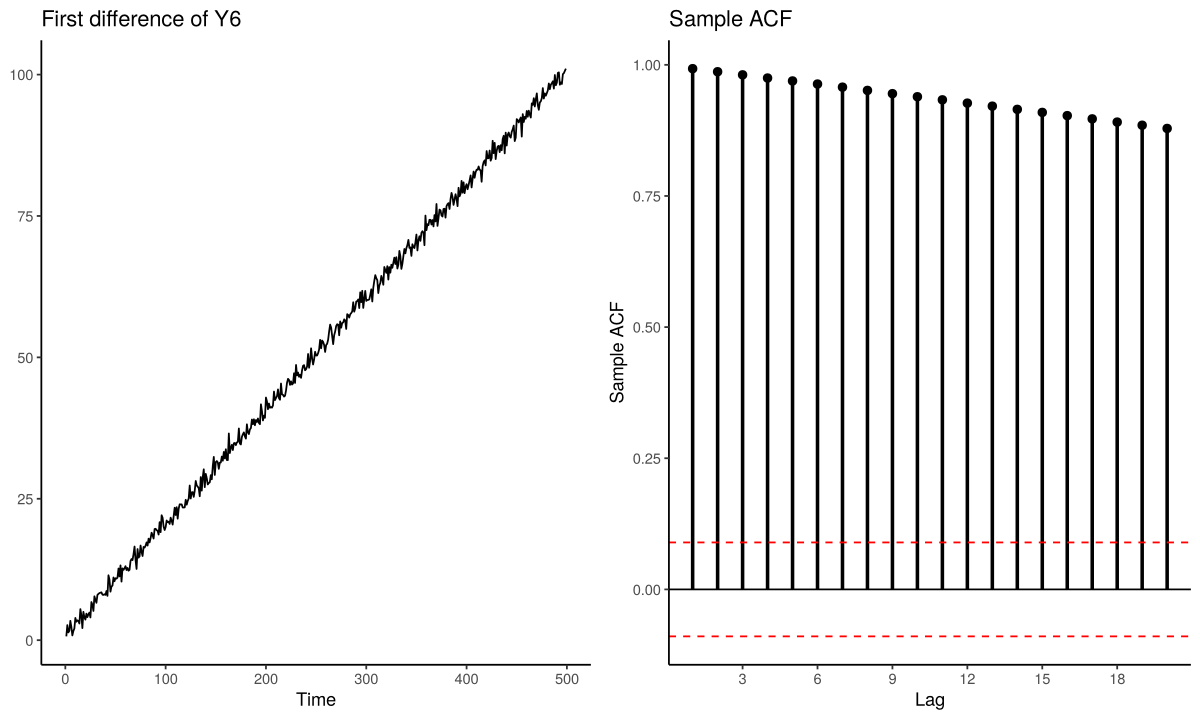

In [13]:
# Y6: the trend regression, then the behaviour of the difference
r6  <- df_report(y6, type = "trend", label = "Y6"); cat("\n")
dy6 <- diff(y6)
cat("Regression of diff(Y6) on a constant and trend (index 1 = period 2):\n")
print(round(summary(lm(dy6 ~ seq_along(dy6)))$coefficients, 4)); cat("\n")
r6b <- df_report(dy6, type = "trend", label = "diff(Y6)")
ts_acf_panel(dy6, title = "First difference of Y6")

**Reading the output.** $\tau_\tau=0.74$: no evidence against the unit root ($\hat\gamma\approx2\times10^{-5}$). $\Phi_3$ is enormous, so $\delta=\gamma=0$ is rejected: the trend term is needed, and comparing the $t$-ratio on $\gamma$ (0.74) with the normal distribution still does not reject. The differences confirm the picture. Regressing $\Delta Y_6$ on a constant and trend gives a slope of 0.2002 (true 0.2) and an intercept of 0.69 (true $0.5+0.2=0.7$, because the index starts at period 2), and the DF trend test on $\Delta Y_6$ rejects decisively ($\tau_\tau=-23.5$). $Y_6$ is $I(1)$ with **both** a stochastic trend and a deterministic trend in its differences, which is why its level grows quadratically. The plot of $\Delta Y_6$ shows the linear trend, and its sample ACF decays slowly because of it; once detrended, $\Delta Y_6$ is white noise.

## Summary of the six cases

| Series | Start with | Path through the procedure | Conclusion |
|---|---|---|---|
| $Y_1$ | none | $\tau$ rejects | $I(0)$, zero mean |
| $Y_2$ | drift | $\tau_\mu$ rejects | $I(0)$ with a nonzero mean |
| $Y_3$ | trend | $\tau_\tau$ rejects | trend-stationary |
| $Y_4$ | drift | $\tau_\mu$ and $\Phi_1$ do not reject → none: $\tau$ does not reject; $\Delta Y_4$ rejects | $I(1)$, no drift |
| $Y_5$ | trend | $\tau_\tau$ and $\Phi_3$ do not reject → drift: $\tau_\mu$ does not reject, $\Phi_1$ rejects; mean of $\Delta Y_5$ significant | $I(1)$ with drift |
| $Y_6$ | trend | $\tau_\tau$ does not reject, $\Phi_3$ rejects; $\gamma=0$ not rejected; $\Delta Y_6$ trend-stationary | $I(1)$ with a trend in the differences |

> **A caution.** These series are artificial, long ($T=500$) and generated by exactly the models the tests assume. Real economic series are shorter, may have breaks, changing volatility or MA components, and rarely give such a clear picture (Section 11).

# 8&nbsp;&nbsp;Phillips–Perron and KPSS: confirmatory analysis

## Phillips–Perron

The ADF test handles serial correlation **parametrically**, by adding lags. Phillips and Perron (1988) instead estimate the non-augmented DF regression and correct its $t$-ratio **non-parametrically**:

$$
Z_\tau=\frac{\hat\sigma}{\hat\lambda}\,\tau-\frac{\hat\lambda^2-\hat\sigma^2}{2\hat\lambda}\cdot\frac{T\,\operatorname{SE}(\hat\gamma)}{s},
$$

where $\hat\sigma^2$ is the residual variance, $s$ the regression standard error and $\hat\lambda^2$ a Newey–West estimate of the **long-run variance** $\lambda^2=\sum_{j=-\infty}^{\infty}\gamma_j$ of the errors. With white-noise errors $\lambda^2=\sigma^2$ and $Z_\tau=\tau$. Under $H_0$, $Z_\tau$ has the same limit as $\tau$ for the same deterministic terms, so the DF critical values apply. PP is robust to general serial correlation and heteroskedasticity, but it is badly over-sized when the errors have a large negative MA root (Schwert 1989; Section 9).

## KPSS

Kwiatkowski, Phillips, Schmidt and Shin (1992) reverse the hypotheses. Write

$$
Y_t=\delta t+r_t+u_t,\qquad r_t=r_{t-1}+\eta_t,\qquad \eta_t\sim\text{WN}(0,\sigma^2_\eta),
$$

with $u_t$ stationary. If $\sigma^2_\eta=0$, the random walk $r_t$ is a constant and $Y_t$ is stationary around a level ($\delta=0$) or a trend: this is $H_0$. If $\sigma^2_\eta>0$, $Y_t$ has a unit root. Let $\hat e_t$ be the residuals from regressing $Y_t$ on a constant (or on a constant and trend) and $\hat S_t=\sum_{j=1}^{t}\hat e_j$ their partial sums. Then

$$
\text{KPSS}=\frac{1}{T^2\hat\lambda^2}\sum_{t=1}^{T}\hat S_t^{\,2},
$$

with $\hat\lambda^2$ again a long-run variance estimate. Under stationarity the partial sums stay small; under a unit root they wander and the statistic is large. It is a **right-tailed** test with 5% critical values 0.463 (level) and 0.146 (trend).

## Using both

Unit-root tests have low power, and stationarity tests over-reject for highly persistent stationary series, so neither is conclusive alone. Comparing the two — *confirmatory analysis* — gives four outcomes:

| | KPSS does not reject (stationary) | KPSS rejects |
|---|---|---|
| **ADF/PP reject** (no unit root) | stationary — consistent | conflict: breaks, long memory or a near-unit root |
| **ADF/PP do not reject** | conflict: data uninformative, low power | unit root — consistent |

### Predict

For $Y_2$–$Y_5$ of Section 7, which cell of this table should each series land in?

In [14]:
# Confirmatory analysis on Y2-Y5: ADF (BIC lags), Phillips-Perron and KPSS
confirm <- function(y, trend) {
  pmax <- floor(12 * (length(y) / 100)^0.25)
  a <- ur.df(y, type = if (trend) "trend" else "drift", lags = pmax, selectlags = "BIC")
  p <- ur.pp(y, type = "Z-tau", model = if (trend) "trend" else "constant", lags = "short")
  k <- ur.kpss(y, type = if (trend) "tau" else "mu", lags = "short")
  c(ADF = a@teststat[1], `ADF 5%` = a@cval[1, "5pct"],
    PP  = p@teststat[1], `PP 5%`  = p@cval[1, "5pct"],
    KPSS = k@teststat[1], `KPSS 5%` = k@cval[1, "5pct"])
}
tab <- rbind(`Y2 (level)`       = confirm(y2, trend = FALSE),
             `Y3 (trend)`       = confirm(y3, trend = TRUE),
             `Y4 (level)`       = confirm(y4, trend = FALSE),
             `Y5 (trend)`       = confirm(y5, trend = TRUE))
print(round(tab, 3))
verdict <- data.frame(`ADF rejects unit root`    = tab[, "ADF"]  < tab[, "ADF 5%"],
                      `PP rejects unit root`     = tab[, "PP"]   < tab[, "PP 5%"],
                      `KPSS rejects stationarity` = tab[, "KPSS"] > tab[, "KPSS 5%"],
                      check.names = FALSE)
cat("\n"); print(verdict)

              ADF ADF 5%     PP  PP 5%  KPSS KPSS 5%
Y2 (level) -7.929  -2.87 -8.787 -2.868 0.103   0.463
Y3 (trend) -7.942  -3.42 -8.781 -3.421 0.080   0.146
Y4 (level) -1.283  -2.87 -1.365 -2.868 3.996   0.463
Y5 (trend) -2.424  -3.42 -2.361 -3.421 0.605   0.146


           ADF rejects unit root PP rejects unit root KPSS rejects stationarity
Y2 (level)                  TRUE                 TRUE                     FALSE
Y3 (trend)                  TRUE                 TRUE                     FALSE
Y4 (level)                 FALSE                FALSE                      TRUE
Y5 (trend)                 FALSE                FALSE                      TRUE


**Reading the output.** All four series land in consistent cells. For $Y_2$ and $Y_3$, ADF and PP reject the unit root by a wide margin while KPSS (0.103 and 0.080) is far below its critical value: stationary around a level and around a trend respectively. For $Y_4$ and $Y_5$, ADF and PP do not reject, while KPSS rejects stationarity (3.996 and 0.605): unit roots. With $T=500$ and no complications the three tests agree; Section 11 shows a real series for which they do not. (The ADF statistics differ slightly from Section 7 because urca's BIC search always includes at least one lagged difference and drops the first $p_{\max}$ observations.)

# 9&nbsp;&nbsp;Size, power and lag length in practice

Unit-root tests are notorious for two problems.

- **Low power.** A stationary AR(1) with $\phi=0.95$ differs from a random walk only in the long run, and a sample of $T=100$ carries little information about the long run. Power falls further when superfluous deterministic terms are included (Section 10.1 puts numbers on this).
- **Size distortions.** When $\Delta Y_t$ has a large **negative** MA root — the random-walk-plus-noise model of Section 2 is one example, an over-differenced series another — the MA root nearly cancels the AR unit root, the series behaves almost like white noise, and tests reject a true unit root far too often (Schwert 1989).

Some practical lessons:

1. **Span beats frequency.** Power depends on the length of time covered, not on the number of observations: 30 years of monthly data carry little more information about mean reversion than 30 annual observations (Shiller and Perron 1985).
2. **Lag selection matters most when MA roots are large.** BIC tends to choose too few lags in that case and AIC more; the modified AIC of Ng and Perron (2001) was designed for exactly this problem (Section 10.1).
3. **Seasonality.** Add seasonal dummies if seasonality is deterministic, and use seasonal unit-root tests (Hylleberg, Engle, Granger and Yoo 1990) if roots may lie at seasonal frequencies. Seasonal-adjustment filters can bias tests towards non-rejection (Ghysels and Perron 1993).
4. **Breaks** in the level or slope of a trend make a stationary series look like a unit root (Section 10.2).

### Predict before you simulate

The true model is a random walk whose differences are MA(1), $\Delta Y_t=\varepsilon_t+\beta\varepsilon_{t-1}$, with $\beta=0,\,-0.5,\,-0.8$ and $T=100$, so the unit-root null is **true**. All tests include a constant and have nominal size 5%. How often will (a) the DF test without lags, (b) ADF with lags chosen by BIC, (c) ADF with lags chosen by AIC and (d) Phillips–Perron reject?

In [15]:
# Size of unit-root tests when the differences have a negative MA root (H0 is true)
# adf_tau(): fast ADF t-ratio with p chosen by AIC/BIC over 0..pmax on a common sample
adf_tau <- function(y, type = c("drift", "none", "trend"), pmax = 0,
                    ic = c("BIC", "AIC", "fixed")) {
  type <- match.arg(type); ic <- match.arg(ic)
  dy <- diff(y); n <- length(dy); rows <- (pmax + 1):n; m <- length(rows)
  X0 <- switch(type, none  = cbind(y[rows]),
                     drift = cbind(1, y[rows]),
                     trend = cbind(1, rows, y[rows]))
  L  <- matrix(0, m, pmax); for (j in seq_len(pmax)) L[, j] <- dy[rows - j]
  fit_p <- function(p) {
    X <- cbind(X0, L[, seq_len(p), drop = FALSE])
    XtXi <- solve(crossprod(X)); b <- XtXi %*% crossprod(X, dy[rows])
    rss <- sum((dy[rows] - X %*% b)^2); k <- ncol(X); g <- ncol(X0)
    list(ic  = m * log(rss / m) + k * (if (ic == "AIC") 2 else log(m)),
         tau = b[g] / sqrt(rss / (m - k) * XtXi[g, g]))
  }
  fits <- lapply(0:pmax, fit_p)
  best <- if (ic == "fixed") pmax + 1 else which.min(sapply(fits, `[[`, "ic"))
  c(tau = fits[[best]]$tau, p = best - 1)
}

set.seed(123)
R <- 1000; T <- 100; betas <- c(0, -0.5, -0.8)
size <- sapply(betas, function(b) rowMeans(replicate(R, {
  y <- cumsum(as.numeric(arima.sim(model = list(ma = b), n = T)))
  c(`DF, no lags`     = df_tau(y, "drift") < -2.89,
    `ADF, BIC lags`   = adf_tau(y, "drift", pmax = 12, ic = "BIC")[["tau"]] < -2.89,
    `ADF, AIC lags`   = adf_tau(y, "drift", pmax = 12, ic = "AIC")[["tau"]] < -2.89,
    `Phillips-Perron` = { pp <- ur.pp(y, type = "Z-tau", model = "constant", lags = "short")
                          pp@teststat < pp@cval[1, "5pct"] })
})))
colnames(size) <- paste("beta =", betas)
cat("Rejection rates of a TRUE unit root, nominal size 5%:\n"); print(round(size, 3))

Rejection rates of a TRUE unit root, nominal size 5%:


                beta = 0 beta = -0.5 beta = -0.8
DF, no lags        0.049       0.561       0.996
ADF, BIC lags      0.045       0.202       0.696
ADF, AIC lags      0.065       0.131       0.452
Phillips-Perron    0.055       0.444       0.986


**Reading the output.** With $\beta=0$ all four tests have about the right size (4.5–6.5%). With $\beta=-0.5$ the DF test without lags rejects the true unit root 56% of the time and PP 44%; with $\beta=-0.8$ both reject in virtually every sample (99.6% and 98.6%). Augmentation helps but does not cure the problem: ADF with BIC lags rejects 20% and 70% of the time, ADF with AIC lags 13% and 45%. AIC does better because it picks longer lags, and long lags are needed to approximate an MA root near $-1$ by an autoregression. Three practical consequences: do not rely on PP when the differences show strong negative autocorrelation; err on the generous side when choosing the ADF lag; and prefer lag rules designed for this case, such as Ng and Perron's MAIC (Section 10.1).

## Exercises

### Exercise 1 — A Dickey–Fuller test by hand
With $T=100$ annual observations, OLS gives
$\Delta\hat y_t=0.42+0.003\,t-0.12\,y_{t-1}+0.35\,\Delta y_{t-1}$, with $\operatorname{SE}(\hat\gamma)=0.045$ and residual sum of squares 50.2. Re-estimating with $\delta=\gamma=0$ imposed gives a residual sum of squares of 53.6. (a) Compute $\tau_\tau$ and $\Phi_3$ (remember to count the observations lost to the lag). (b) What do you conclude at 5%? (c) What would you estimate next, according to Section 7?

### Exercise 2 — Component form and the $\Phi$ tests
For $Y_t=\mu+\delta t+u_t$ with $u_t=\phi u_{t-1}+\varepsilon_t$, (a) derive the DF regression $\Delta Y_t=c+\delta^\ast t+\gamma Y_{t-1}+\varepsilon_t$ and express $c,\delta^\ast,\gamma$ in terms of $\mu,\delta,\phi$. (b) Show that $\gamma=0$ implies $\delta^\ast=0$, and explain why this makes $\Phi_3$ a natural test. (c) Use your answer to recover $\mu$ and $\delta$ from the $Y_2$ and $Y_3$ regressions of Section 7.

### Exercise 3 — Over-differencing
Let $Y_t=\mu+\delta t+u_t$ with $u_t=\phi u_{t-1}+\varepsilon_t$, $|\phi|<1$. (a) Show that $\Delta Y_t$ is an ARMA(1,1) with an MA unit root. (b) Show that its first autocorrelation is $-(1-\phi)/2$. (c) Check the result by simulation for $\phi=0.5$ and $T=1000$, and compare with Section 4.





## Suggested reading

- Enders, W. (2015), *Applied Econometric Time Series*, 4th ed., Wiley: Ch. 4 (trends, DF/ADF tests and the testing procedure of Section 7, structural change, PP, KPSS, DF-GLS).
- Hamilton, J. D. (1994), *Time Series Analysis*, Princeton University Press: Chs. 15–17 (trend models, unit-root asymptotics and tests).
- Pfaff, B. (2008), *Analysis of Integrated and Cointegrated Time Series with R*, 2nd ed., Springer: Chs. 3–6 — the companion to **urca**.
- Choi, I. (2015), *Almost All About Unit Roots: Foundations, Developments, and Applications*, Cambridge University Press — a modern survey, including breaks, panel and nonlinear tests.
- Maddala, G. S. and Kim, I.-M. (1998), *Unit Roots, Cointegration, and Structural Change*, Cambridge University Press.
- Hyndman, R. J. and Athanasopoulos, G., *Forecasting: Principles and Practice*, 3rd ed., Section 9.1 (stationarity and differencing), free online at [otexts.com/fpp3](https://otexts.com/fpp3/).
- Elder, J. and Kennedy, P. E. (2001), "Testing for unit roots: what should students be taught?", *Journal of Economic Education* 32(2), 137–146 — a short, practical guide to the testing strategy.

**Original papers.**

*Foundations:* Granger and Newbold (1974, *J. Econometrics*); Dickey and Fuller (1979, *JASA*; 1981, *Econometrica*); Beveridge and Nelson (1981, *JME*); Nelson and Kang (1981, *Econometrica*); Nelson and Plosser (1982, *JME*); Said and Dickey (1984, *Biometrika*); Phillips (1986, *J. Econometrics*; 1987, *Econometrica*); Campbell and Mankiw (1987, *QJE*); Dickey and Pantula (1987, *JBES*); Phillips and Perron (1988, *Biometrika*); West (1988, *Econometrica*); Dolado, Jenkinson and Sosvilla-Rivero (1990, *J. Economic Surveys*); Kwiatkowski, Phillips, Schmidt and Shin (1992, *J. Econometrics*); MacKinnon (1996, *J. Applied Econometrics*).

*Power, size and lag length:* Shiller and Perron (1985, *Economics Letters*); Schwert (1989, *JBES*); Ghysels and Perron (1993, *J. Econometrics*); Ng and Perron (1995, *JASA*); Elliott, Rothenberg and Stock (1996, *Econometrica*); Ng and Perron (2001, *Econometrica*); Müller and Elliott (2003, *Econometrica*); Perron and Qu (2007, *Economics Letters*).

*Breaks:* Perron (1989, *Econometrica*); Zivot and Andrews (1992, *JBES*); Lumsdaine and Papell (1997, *REStat*); Lee and Strazicich (2003, *REStat*); Becker, Enders and Lee (2006, *J. Time Series Analysis*); Narayan and Popp (2010, *J. Applied Statistics*); Enders and Lee (2012, *Oxford Bulletin of Economics and Statistics*).

*Robust and bootstrap methods:* Cavaliere (2004, *Econometric Reviews*); Cavaliere and Taylor (2007, *J. Econometrics*; 2008, *Econometric Theory*); Palm, Smeekes and Urbain (2008, *J. Time Series Analysis*); Harvey, Leybourne and Taylor (2009, *Econometric Theory*).

*Explosive roots:* Phillips, Wu and Yu (2011, *International Economic Review*); Phillips, Shi and Yu (2015, *International Economic Review*); Vasilopoulos, Pavlidis and Martínez-García (2022, *Journal of Statistical Software* 103(10)).

*Persistence and low-frequency inference:* Stock (1991, *JME*); Hansen (1999, *REStat*); Müller and Watson (2008, *Econometrica*; 2018, *Econometrica*).

*Other strands (Section 10.6):* Granger and Joyeux (1980, *J. Time Series Analysis*); Hosking (1981, *Biometrika*); Geweke and Porter-Hudak (1983, *J. Time Series Analysis*); Hylleberg, Engle, Granger and Yoo (1990, *J. Econometrics*); Canova and Hansen (1995, *JBES*); Levin, Lin and Chu (2002, *J. Econometrics*); Kapetanios, Shin and Snell (2003, *J. Econometrics*); Im, Pesaran and Shin (2003, *J. Econometrics*); Pesaran (2007, *J. Applied Econometrics*); Hyndman and Khandakar (2008, *J. Statistical Software*).

*Data:* Cobb (1978, *Biometrika*) on the Nile; Schotman and van Dijk (1991, *J. Applied Econometrics*) for the extended Nelson–Plosser data.

*Surveys of applied use:* Rath and Akram (2021), "Popularity of unit root tests: a review", *Asian Economics Letters* 2(4).

## Appendix A: R quick reference

| Task | Function | Notes |
|---|---|---|
| (A)DF test | `urca::ur.df(y, type, lags, selectlags)` | `type = "none"/"drift"/"trend"`; with `"AIC"`/`"BIC"`, `lags` is the maximum and the search starts at 1 |
| Readable DF output | `df_report(y, type, lags, selectlags)` | this lecture's helper: regression, $\tau$/$\Phi$ vs 5% c.v., MacKinnon $p$ |
| MacKinnon $p$-values | `urca::punitroot(q, N, trend = "nc"/"c"/"ct")` | `qunitroot()` gives critical values for any $T$ |
| Phillips–Perron | `urca::ur.pp(y, type = "Z-tau", model, lags = "short"/"long")` | Newey–West bandwidth |
| KPSS | `urca::ur.kpss(y, type = "mu"/"tau", lags = "short"/"long")` | $H_0$: stationarity |
| DF-GLS, ERS $P_T$ | `urca::ur.ers(y, type = "DF-GLS"/"P-test", model = "constant"/"trend", lag.max)` | GLS detrending |
| Zivot–Andrews | `urca::ur.za(y, model = "intercept"/"trend"/"both", lag)` | `@bpoint`: last period before the break |
| Schmidt–Phillips LM | `urca::ur.sp(y, type, pol.deg)` | LM test with polynomial trend |
| Quick ADF | `tseries::adf.test(y, k)` | always constant + trend; default `k = trunc((T-1)^(1/3))` |
| Explosive roots | `exuber::radf()`, `radf_mc_cv()`, `datestamp()` | SADF/GSADF and date-stamping |
| Number of differences | `forecast::ndiffs(y)`, `forecast::nsdiffs(y)` | KPSS-based (regular) and seasonal |
| ARIMA with drift | `arima(diff(y), order = c(p, 0, q))` or `forecast::Arima(y, order, include.drift = TRUE)` | `arima()` drops the constant when $d\ge1$ |